# Report figures — Multi-Register Encoding paper

Self-contained reproductions of the *data* figures in
`Multi_register_Quantum_Encoding.pdf` (the two circuit diagrams live in
`diagram_multi_register.py` / the drawn figures, not here). Figs. 3 and 4
(infidelity + reweighting-success histogram) are combined into one
side-by-side figure below since they're the natural pair to compare; Figs.
5 and 6 (shadow overlap, Haar scaling) keep their own paper figure numbers.

Each section below **only reads files already saved to disk** in this folder
(pickles, json, npz, csv) — no upstream notebook needs to be re-run first.
Each section's top comment names the exact notebook + cell the figure was
first produced in, so if you regenerate the underlying data (e.g. a new
seed sweep, a new hardware run) you know which notebook to go re-run before
re-executing the cell here.

**Shared report style**, used identically in every cell below (own copy per
cell so each stays copy-paste standalone): no top/right axis border, muted
left/bottom border, matching grid, `pdf.fonttype=42` so PDF text stays
selectable/editable, and a uniform borderless-but-legible legend style.
Color convention: **red = un-preconditioned / baseline**, **blue =
preconditioned**, **black = direct / full-state / reference** — held
consistent across every figure that shares that comparison (Figs. 3 & 4).
Fig. 6's line colors encode a different variable (row length N) and are
deliberately left as their own categorical palette.

Only styling (labels, colors, titles) should need touching in this notebook —
edit and re-run the cell, nothing else.

## Fig. — The R75 dataset: full (a) and condensed (b)

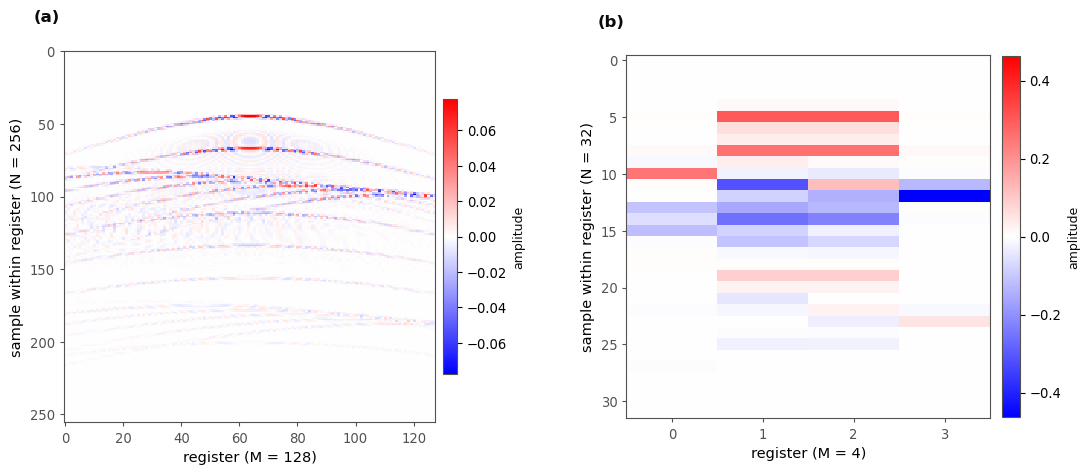

Full R75:      shape=(256, 128)   ||Y_full||=1.000000
Condensed R75: shape=(32, 4)   ||Y_small||=1.000000


In [1]:
# SOURCE: MainMREnotebook.ipynb, cell 4 (panel a: full R75 image) + cell 5 & 6 (panel b: condensed heatmap).
# Panel (b) is the exact 4x32 downsample used for the Quantinuum H2-1 hardware run (Fig. 5 above) --
# M=4 registers x N=32, matching "Hardware Results": M=4 preparation registers, n=log2(32)=5 qubits each.
# No titles here (captions live in the LaTeX \caption) -- only the (a)/(b) tags.
# Both panels: same diverging colormap (data is signed real amplitude, not magnitude), same axis
# orientation (x = register/M, y = sample-within-register/N, matching between panels so neither
# reads as transposed relative to the other), and the same square box aspect so the two panels sit
# at the same visual size regardless of their very different M x N shapes.
# Reads only the raw R75 excel sheet -- nothing upstream needs to be run first.
#   R75 Ultrasound data.xlsx
# To show a different downsample size, change the resize() targets below (they must match whatever
# M x N split the rest of the pipeline actually used, or the two won't correspond to real runs).
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.transform import resize

BASE = os.getcwd()
CMAP = "bwr"

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"

def frame(ax):
    """Image panels keep a thin full frame (unlike tidy()'s open top/right for line/scatter
    panels elsewhere in this notebook) -- a heatmap reads oddly with no border at all."""
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)

_df = pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None)

Y_full = resize(_df.to_numpy(), (256, 128), anti_aliasing=True)     # (N=256 samples, M=128 registers)
Y_full = Y_full / np.linalg.norm(Y_full)

Y_small = resize(_df.to_numpy(), (32, 4), anti_aliasing=True)       # (N=32 samples, M=4 registers)
Y_small = Y_small / np.linalg.norm(Y_small)

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5}):
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.0, 5.2))

    # ---- (a) full R75, 256 x 128 -- both axes plotted directly: x=register(M), y=sample(N) ----
    imgL = Y_full                       # (256, 128): rows=N (samples), cols=M (registers) -- as-is
    vmaxL = np.abs(imgL).max()
    imL = axL.imshow(imgL, aspect="auto", cmap=CMAP, interpolation="nearest", vmin=-vmaxL, vmax=vmaxL)
    axL.set_xlabel("register (M = 128)"); axL.set_ylabel("sample within register (N = 256)")
    axL.set_box_aspect(1)
    cbL = fig.colorbar(imL, ax=axL, fraction=0.035, pad=0.02)
    cbL.outline.set_edgecolor(MUTED); cbL.set_label("amplitude", fontsize=9, color=INK)
    frame(axL)

    # ---- (b) condensed 4 x 32 -- SAME orientation: x=register(M), y=sample(N), no transpose ----
    imgR = Y_small                      # (32, 4): rows=N (samples), cols=M (registers) -- matches (a)
    vmaxR = np.abs(imgR).max()
    imR = axR.imshow(imgR, aspect="auto", cmap=CMAP, interpolation="nearest", vmin=-vmaxR, vmax=vmaxR)
    axR.set_xlabel("register (M = 4)"); axR.set_ylabel("sample within register (N = 32)")
    axR.set_xticks(range(imgR.shape[1]))
    axR.set_box_aspect(1)
    cbR = fig.colorbar(imR, ax=axR, fraction=0.046, pad=0.03)
    cbR.outline.set_edgecolor(MUTED); cbR.set_label("amplitude", fontsize=9, color=INK)
    frame(axR)

    for ax, tag in ((axL, "(a)"), (axR, "(b)")):
        ax.text(-0.08, 1.07, tag, transform=ax.transAxes, fontsize=12,
                fontweight="bold", color=INK, va="bottom", ha="left")

    fig.tight_layout(w_pad=4.0)
    fig.savefig(os.path.join(BASE, "fig_R75_full_and_condensed.pdf"), bbox_inches="tight")
    plt.show()

print(f"Full R75:      shape={Y_full.shape}   ||Y_full||={np.linalg.norm(Y_full):.6f}")
print(f"Condensed R75: shape={Y_small.shape}   ||Y_small||={np.linalg.norm(Y_small):.6f}")

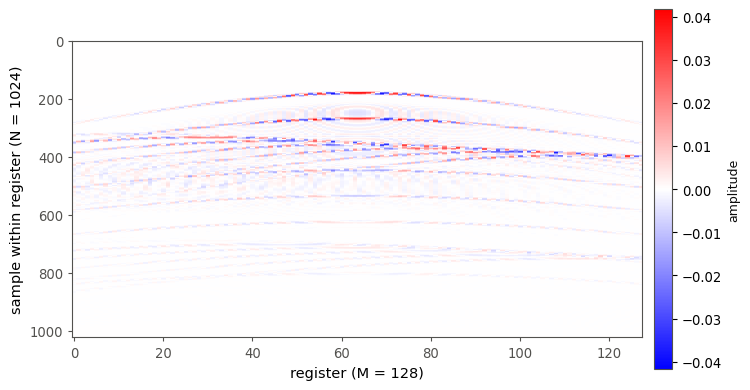

raw excel      : (382, 128)  (samples, registers)
upscaled R75   : shape=(1024, 128)   ||Y||=1.000000
partition      : M = 128 registers x N = 1024 samples  -> n = 10 + m = 7 = 17 qubits
sigma_i        : sum sigma^2 = 1.0000000000   min 0.0299  max 0.1604


In [11]:
# SOURCE: replaces the old two-panel (full 256x128 + condensed 4x32) dataset figure.
# The paper now uses ONE dataset throughout -- the 4x upscaled R75, M = 128 registers of
# N = 1024 samples -- for both the numerical results (Figs. 3-4) and the H2-1 hardware
# demonstration, so there is no second "condensed" panel to show any more.
#
# The upscale: resize(raw (382,128) -> (1024,128)) resamples the SAMPLE axis only, 382 -> 1024.
# The register axis stays at its native 128 -- no interpolation across registers. Note this is
# skimage's default BI-LINEAR interpolation (order=1), not bicubic.
# n = log2(1024) = 10 qubits per register, m = log2(128) = 7 index qubits, 17 total.
#
# No title (the caption lives in the LaTeX \caption) and no (a)/(b) tag, since it is one panel.
# Same report style as every other figure cell here: bwr diverging map (the data is signed real
# amplitude, not magnitude), muted full frame, muted colourbar edge, pdf.fonttype=42.
# Reads only the raw R75 excel sheet -- nothing upstream needs to be run first.
#   R75 Ultrasound data.xlsx
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.transform import resize

BASE = os.getcwd()
CMAP = "bwr"

FULL_N, FULL_M = 1024, 128          # samples per register, registers
FIGSIZE    = (7.6, 4.4)             # overall canvas
BOX_ASPECT = 0.52                   # panel height / width -- < 1 is landscape. Raise toward
                                    # 1.0 for a square panel, lower for a longer, flatter one.

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"

def frame(ax):
    """Image panels keep a thin full frame -- a heatmap reads oddly with no border at all."""
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)

_df  = pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None)
Y_x4 = resize(_df.to_numpy(), (FULL_N, FULL_M), anti_aliasing=True)   # (1024, 128)
Y_x4 = Y_x4 / np.linalg.norm(Y_x4)

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5}):
    fig, ax = plt.subplots(figsize=FIGSIZE)

    vmax = np.abs(Y_x4).max()        # symmetric limits so white sits exactly at zero amplitude
    im = ax.imshow(Y_x4, aspect="auto", cmap=CMAP, interpolation="nearest",
                   vmin=-vmax, vmax=vmax)
    ax.set_xlabel(f"register (M = {FULL_M})")
    ax.set_ylabel(f"sample within register (N = {FULL_N})")
    ax.set_box_aspect(BOX_ASPECT)

    cb = fig.colorbar(im, ax=ax, fraction=0.030, pad=0.02)
    cb.outline.set_edgecolor(MUTED); cb.set_label("amplitude", fontsize=9, color=INK)
    frame(ax)

    fig.tight_layout()
    fig.savefig(os.path.join(BASE, "fig_R75x4_dataset.pdf"), bbox_inches="tight")
    plt.show()

_rn    = np.linalg.norm(Y_x4.T, axis=1)
_sigma = _rn / np.linalg.norm(_rn)
print(f"raw excel      : {_df.shape}  (samples, registers)")
print(f"upscaled R75   : shape={Y_x4.shape}   ||Y||={np.linalg.norm(Y_x4):.6f}")
print(f"partition      : M = {FULL_M} registers x N = {FULL_N} samples  "
      f"-> n = {int(np.log2(FULL_N))} + m = {int(np.log2(FULL_M))} = "
      f"{int(np.log2(FULL_N*FULL_M))} qubits")
print(f"sigma_i        : sum sigma^2 = {(_sigma**2).sum():.10f}   "
      f"min {_sigma.min():.4f}  max {_sigma.max():.4f}")


## Fig. 3 & 4 — Full R75: infidelity (a) and reweighting success (b), side by side

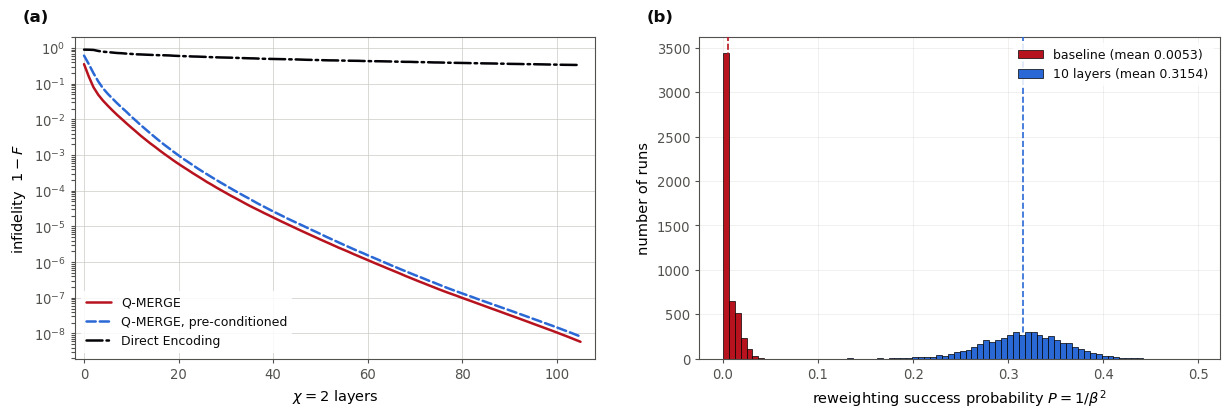

panel (a) @ 10 layers: orig 5.879e-03 -> preconditioned 1.195e-02  (direct/full-state 6.820e-01)
panel (b): v_full_seed7.pkl  baseline 0.0053 -> 10 layers 0.3154  (60.1x)


In [2]:
# SOURCE: MainMREnotebook.ipynb, cell 29 (panel a: infidelity) + cell 24 & 74 (panel b: histogram).
#         Panel (a) is RE-DERIVED per the paper's corrected aggregate-fidelity definition (2026-10-02):
#         F = ( sum_i |sigma_i|^2 sqrt(F_i) )^2  -- the sigma_i^2-weighted sum of row AMPLITUDES,
#         squared. This supersedes the 2026-09-04 form F = sum_i |sigma_i|^2 F_i (its first-order
#         approximation), which itself replaced the original F = prod_i F_i.
#         sigma_i are each row's target weight, computed exactly as
#         normalised Y_full image, i.e. sigma_i = ||Y_full[:, i]|| (since ||Y_full|| = 1).
#
# No chart title (caption lives in LaTeX) -- only the (a)/(b) tags.
# Panels share one color key so they read as a single comparison:
#   RED  = un-preconditioned  ("multi-register" / histogram "baseline")
#   BLUE = preconditioned     ("multi-register, pre-conditioned" / histogram "10 layers")
#   BLACK = direct / full-state (panel a only -- there's no "direct" curve on the histogram)
#
# Reads, all off disk, nothing upstream needs to be re-run:
#   SSO results/row_sweep_R75full_orig/row_fids.json               <- un-preconditioned rows (a)
#   SSO results/row_sweep_R75full_brickwallFIXED_L10/row_fids.json <- preconditioned rows (a)
#   C:/qruns/fullstate_R75full/checkpoint.npz (or the OneDrive copy)  <- direct/full-state (a)
#   R75 Ultrasound data.xlsx                                        <- recomputes sigma_i (a)
#   results/v_full_seed*.pkl                                        <- best-seed reweighting sweep (b)
# To swap in different data: change the run_name strings / FLAT_L below -- everything else follows.
import glob, json, os, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from skimage.transform import resize

BASE = os.getcwd()

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

# ================= panel (a): infidelity vs. layers =================
_df = pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None)
Y_full = resize(_df.to_numpy(), (256, 128), anti_aliasing=True)
Y_full = Y_full / np.linalg.norm(Y_full)                  # (256 samples, 128 registers), ||Y_full|| = 1
row_norms = np.linalg.norm(Y_full.T, axis=1)               # ||row_i||, row i = Y_full[:, i]
sigma = row_norms / np.linalg.norm(row_norms)               # sigma_i, sum(sigma_i^2) = 1
M_ROWS = len(sigma)

def combined_infid(run_name):
    """1 - F, with F = ( sum_i |sigma_i|^2 sqrt(F_i(layer)) )^2 -- the paper's corrected
    aggregate fidelity: the sigma_i^2-weighted sum of row AMPLITUDES, squared. (The old
    weighted sum of F_i is its first-order approximation and over-states F slightly.)"""
    with open(os.path.join(BASE, "SSO results", f"row_sweep_{run_name}", "row_fids.json")) as f:
        d = json.load(f)
    fids = [np.array(d[str(i)]["chi"]["2"]["chi_fids"], float) for i in range(M_ROWS)]
    L = min(len(x) for x in fids)
    F = np.clip(np.array([x[:L] for x in fids]), 0.0, 1.0)   # (M_ROWS, L)
    amp = (sigma[:, None] ** 2 * np.sqrt(F)).sum(axis=0)       # sum_i sigma_i^2 sqrt(F_i) -> (L,)
    F_agg = np.clip(amp ** 2, 0.0, 1.0)
    return np.clip(1.0 - F_agg, 1e-16, None)



infid_A = combined_infid("R75full_orig")
infid_B = combined_infid("R75full_brickwallFIXED_L10")
for _ckpt in (os.path.join(os.getcwd(), "SSO results", "fullstate_R75full", "checkpoint.npz"),
             os.path.join(BASE, "SSO results", "fullstate_R75full", "checkpoint.npz")):
    if os.path.exists(_ckpt):
        with np.load(_ckpt) as ck:
            infid_C = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)
        break
else:
    raise FileNotFoundError("full-state checkpoint.npz not found")

# ================= panel (b): reweighting success histogram =================
FLAT_L = 10                       # flattening depth to show
FLOOR  = 1.0 / 32768                # uniform IPR floor for 15 qubits (guards against a broken run)

cands = []
for p in sorted(glob.glob(os.path.join(BASE, "results", "v_full_seed*.pkl")),
                key=lambda s: int(s.split("seed")[-1].split(".")[0])):
    with open(p, "rb") as f:
        d = pickle.load(f)
    lr = d["layer_results"]
    if FLAT_L not in lr:
        continue
    ratio = lr[FLAT_L]["ipr"] / FLOOR
    assert ratio > 1.05, f"{os.path.basename(p)} is a BROKEN non-unitary run"
    cands.append((lr[FLAT_L]["res"]["mean"], p, d))
assert cands, f"no seed pickle contains layer {FLAT_L}"
best_P, best_path, best_data = max(cands, key=lambda t: t[0])
layer_results, base_result = best_data["layer_results"], best_data["base_result"]

P0, m0 = np.asarray(base_result["P"]), base_result["mean"]
rL = layer_results[FLAT_L]
P1, m1, ipr = np.asarray(rL["res"]["P"]), rL["res"]["mean"], rL.get("ipr")

# ================= figure: two panels, one shared style =================
with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(12.4, 4.3))

    # ---- (a) infidelity ----
    axL.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
    ENDS = []
    for y, c, ls, lab in ((infid_A, RED, "-", "Q-MERGE"),
                          (infid_B, BLUE, "--", "Q-MERGE, pre-conditioned"),
                          (infid_C, BLACK, "-.", "Direct Encoding")):
        keep = np.flatnonzero(y > 1e-16)
        n = min((keep[-1] + 1) if keep.size else len(y), 106)
        axL.semilogy(np.arange(n), y[:n], ls=ls, lw=1.8, color=c, label=lab,
                     solid_capstyle="round", dash_capstyle="round")
        ENDS.append((n - 1, y[n - 1]))
    axL.set_xlabel(r"$\chi=2$ layers"); axL.set_ylabel(r"infidelity  $1-F$")
    axL.set_ylim(min(e[1] for e in ENDS) / 3.0, 2.0)
    axL.set_xlim(-2, max(e[0] for e in ENDS) * 1.03)
    axL.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=20))
    axL.yaxis.set_minor_formatter(NullFormatter())
    style_legend(axL, loc="lower left")
    tidy(axL)

    # ---- (b) reweighting success histogram ----
    bins = np.linspace(min(P0.min(), P1.min()), max(P0.max(), P1.max()) * 1.02, 81)
    axR.grid(alpha=0.3, zorder=0, lw=0.6, color=GRID)
    for P, mean, c, lab in ((P0, m0, RED, f"baseline (mean {m0:.4f})"),
                            (P1, m1, BLUE, f"{FLAT_L} layers (mean {m1:.4f})")):
        axR.hist(P, bins=bins, color=c, edgecolor="black", lw=0.5, label=lab, zorder=2)
        axR.axvline(mean, color=c, ls="--", lw=1.2, zorder=3)
    axR.set_xlabel(r"reweighting success probability $P = 1/\beta^2$")
    axR.set_ylabel("number of runs")
    style_legend(axR, loc="upper right")
    tidy(axR)

    for ax, tag in ((axL, "(a)"), (axR, "(b)")):
        ax.text(-0.10, 1.04, tag, transform=ax.transAxes, fontsize=12,
                fontweight="bold", color=INK, va="bottom", ha="left")

    fig.tight_layout(w_pad=3.0)
    fig.savefig(os.path.join(BASE, "fig_R75_infidelity_and_success.pdf"), bbox_inches="tight")
    plt.show()

print(f"panel (a) @ {FLAT_L} layers: orig {infid_A[FLAT_L]:.3e} -> preconditioned {infid_B[FLAT_L]:.3e}"
      f"  (direct/full-state {infid_C[FLAT_L]:.3e})")
print(f"panel (b): {os.path.basename(best_path)}  baseline {m0:.4f} -> {FLAT_L} layers {m1:.4f}"
      f"  ({m1/m0:.1f}x)")

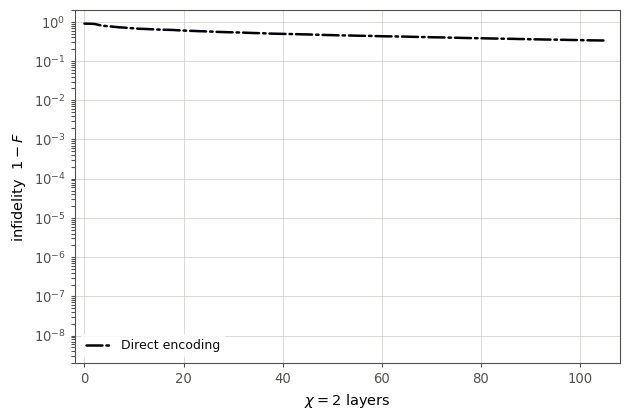

[1_direct] @ layer 10:  Direct encoding 6.820e-01


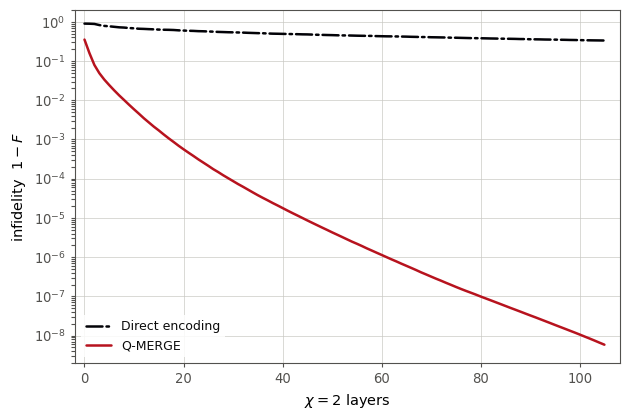

[2_direct_qmerge] @ layer 10:  Direct encoding 6.820e-01   Q-MERGE 5.879e-03


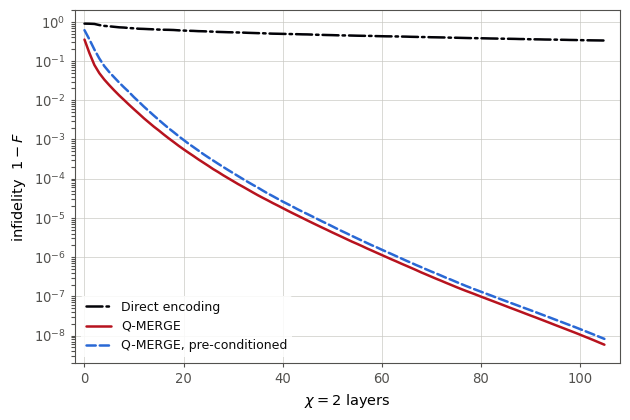

[3_all] @ layer 10:  Direct encoding 6.820e-01   Q-MERGE 5.879e-03   Q-MERGE, pre-conditioned 1.195e-02


In [3]:
# SOURCE: MainMREnotebook.ipynb, cell 29 (panel a: infidelity) + cell 24 & 74 (panel b: histogram).
#         Panel (a) is RE-DERIVED per the paper's corrected aggregate-fidelity definition (2026-10-02):
#         F = ( sum_i |sigma_i|^2 sqrt(F_i) )^2  -- the sigma_i^2-weighted sum of row AMPLITUDES,
#         squared. This supersedes the 2026-09-04 form F = sum_i |sigma_i|^2 F_i (its first-order
#         approximation), which itself replaced the original F = prod_i F_i.
#         sigma_i are each row's target weight, computed exactly as

#
# Produces THREE separate build-up figures for slides, all on the SAME axis scale so they
# overlay cleanly: (1) direct only, (2) direct + Q-MERGE, (3) all three.
#
# RED = Q-MERGE, BLUE = Q-MERGE pre-conditioned, BLACK = direct encoding.
#
# Reads, all off disk, nothing upstream needs to be re-run:
#   SSO results/row_sweep_R75full_orig/row_fids.json               <- un-preconditioned rows
#   SSO results/row_sweep_R75full_brickwallFIXED_L10/row_fids.json <- preconditioned rows
#   C:/qruns/fullstate_R75full/checkpoint.npz (or the OneDrive copy)  <- direct/full-state
#   R75 Ultrasound data.xlsx                                        <- recomputes sigma_i
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from skimage.transform import resize

BASE = os.getcwd()

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

# ================= data =================
_df = pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None)
Y_full = resize(_df.to_numpy(), (256, 128), anti_aliasing=True)
Y_full = Y_full / np.linalg.norm(Y_full)
row_norms = np.linalg.norm(Y_full.T, axis=1)
sigma = row_norms / np.linalg.norm(row_norms)
M_ROWS = len(sigma)

def combined_infid(run_name):
    """1 - F, with F = ( sum_i |sigma_i|^2 sqrt(F_i(layer)) )^2 -- the paper's corrected
    aggregate fidelity: the sigma_i^2-weighted sum of row AMPLITUDES, squared. (The old
    weighted sum of F_i is its first-order approximation and over-states F slightly.)"""
    with open(os.path.join(BASE, "SSO results", f"row_sweep_{run_name}", "row_fids.json")) as f:
        d = json.load(f)
    fids = [np.array(d[str(i)]["chi"]["2"]["chi_fids"], float) for i in range(M_ROWS)]
    L = min(len(x) for x in fids)
    F = np.clip(np.array([x[:L] for x in fids]), 0.0, 1.0)   # (M_ROWS, L)
    amp = (sigma[:, None] ** 2 * np.sqrt(F)).sum(axis=0)       # sum_i sigma_i^2 sqrt(F_i) -> (L,)
    F_agg = np.clip(amp ** 2, 0.0, 1.0)
    return np.clip(1.0 - F_agg, 1e-16, None)


infid_A = combined_infid("R75full_orig")
infid_B = combined_infid("R75full_brickwallFIXED_L10")
for _ckpt in (os.path.join(os.getcwd(), "SSO results", "fullstate_R75full", "checkpoint.npz"),
             os.path.join(BASE, "SSO results", "fullstate_R75full", "checkpoint.npz")):
    if os.path.exists(_ckpt):
        with np.load(_ckpt) as ck:
            infid_C = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)
        break
else:
    raise FileNotFoundError("full-state checkpoint.npz not found")

LINES = {"direct":  (infid_C, BLACK, "-.", "Direct encoding"),
         "orig":    (infid_A, RED,   "-",  "Q-MERGE"),
         "precond": (infid_B, BLUE,  "--", "Q-MERGE, pre-conditioned")}

FIGURES = [
    ("1_direct",       ("direct",)),
    ("2_direct_qmerge", ("direct", "orig")),
    ("3_all",          ("direct", "orig", "precond")),
]

# ---- shared axis scale, computed once from ALL three lines so every figure matches ----
_ends = []
for key, (y, *_ ) in LINES.items():
    keep = np.flatnonzero(y > 1e-16)
    n = min((keep[-1] + 1) if keep.size else len(y), 106)
    _ends.append((n - 1, y[n - 1]))
XLIM = (-2, max(e[0] for e in _ends) * 1.03)
YLIM = (min(e[1] for e in _ends) / 3.0, 2.0)

# ================= plot each figure =================
with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    for name, keys in FIGURES:
        fig, ax = plt.subplots(1, 1, figsize=(6.4, 4.3))
        ax.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
        for key in keys:
            y, c, ls, lab = LINES[key]
            keep = np.flatnonzero(y > 1e-16)
            n = min((keep[-1] + 1) if keep.size else len(y), 106)
            ax.semilogy(np.arange(n), y[:n], ls=ls, lw=1.8, color=c, label=lab,
                       solid_capstyle="round", dash_capstyle="round")
        ax.set_xlabel(r"$\chi=2$ layers"); ax.set_ylabel(r"infidelity  $1-F$")
        ax.set_xlim(*XLIM); ax.set_ylim(*YLIM)
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=20))
        ax.yaxis.set_minor_formatter(NullFormatter())
        style_legend(ax, loc="lower left")
        tidy(ax)
        fig.tight_layout()
        fig.savefig(os.path.join(BASE, f"fig_R75_infidelity_{name}.pdf"), bbox_inches="tight")
        plt.show()
        print(f"[{name}] @ layer 10:  " + "   ".join(f"{LINES[k][3]} {LINES[k][0][10]:.3e}" for k in keys))


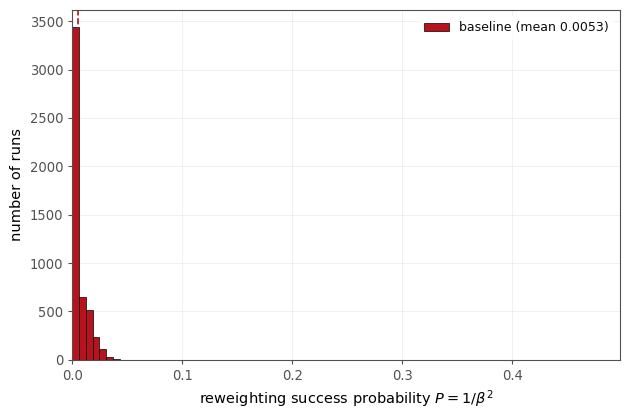

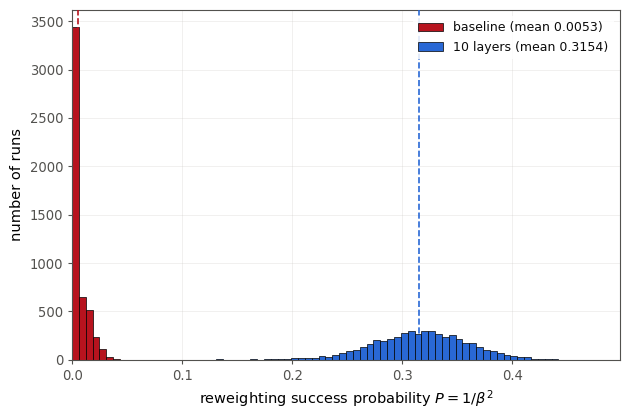

v_full_seed7.pkl  baseline 0.0053 -> 10 layers 0.3154  (60.1x)


In [4]:
# Reweighting success histogram (old panel b), split into a 2-step slide build-up on the
# SAME axis scale: (1) baseline only, (2) baseline + 10 flattening layers.
# RED = baseline, BLUE = 10 layers (same colour key as the infidelity figures).
import glob, os, pickle
import numpy as np
import matplotlib.pyplot as plt

BASE = os.getcwd()

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE = "#b7131e", "#2968d5"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

# ================= data: best-seed reweighting sweep =================
FLAT_L = 10                       # flattening depth to show
FLOOR  = 1.0 / 32768                # uniform IPR floor for 15 qubits (guards against a broken run)

cands = []
for p in sorted(glob.glob(os.path.join(BASE, "results", "v_full_seed*.pkl")),
                key=lambda s: int(s.split("seed")[-1].split(".")[0])):
    with open(p, "rb") as f:
        d = pickle.load(f)
    lr = d["layer_results"]
    if FLAT_L not in lr:
        continue
    ratio = lr[FLAT_L]["ipr"] / FLOOR
    assert ratio > 1.05, f"{os.path.basename(p)} is a BROKEN non-unitary run"
    cands.append((lr[FLAT_L]["res"]["mean"], p, d))
assert cands, f"no seed pickle contains layer {FLAT_L}"
best_P, best_path, best_data = max(cands, key=lambda t: t[0])
layer_results, base_result = best_data["layer_results"], best_data["base_result"]

P0, m0 = np.asarray(base_result["P"]), base_result["mean"]
rL = layer_results[FLAT_L]
P1, m1 = np.asarray(rL["res"]["P"]), rL["res"]["mean"]

SERIES = {"baseline": (P0, m0, RED,  f"baseline (mean {m0:.4f})"),
          "layers":   (P1, m1, BLUE, f"{FLAT_L} layers (mean {m1:.4f})")}

FIGURES = [
    ("1_baseline",        ("baseline",)),
    ("2_baseline_layers", ("baseline", "layers")),
]

# ---- shared axes, computed once from BOTH series so every figure matches ----
bins = np.linspace(min(P0.min(), P1.min()), max(P0.max(), P1.max()) * 1.02, 81)
YMAX = max(np.histogram(P0, bins)[0].max(), np.histogram(P1, bins)[0].max()) * 1.05
XLIM = (bins[0], bins[-1])

# ================= plot each figure =================
with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    for name, keys in FIGURES:
        fig, ax = plt.subplots(1, 1, figsize=(6.4, 4.3))
        ax.grid(alpha=0.3, zorder=0, lw=0.6, color=GRID)
        for key in keys:
            P, mean, c, lab = SERIES[key]
            ax.hist(P, bins=bins, color=c, edgecolor="black", lw=0.5, label=lab, zorder=2)
            ax.axvline(mean, color=c, ls="--", lw=1.2, zorder=3)
        ax.set_xlim(*XLIM); ax.set_ylim(0, YMAX)
        ax.set_xlabel(r"reweighting success probability $P = 1/\beta^2$")
        ax.set_ylabel("number of runs")
        style_legend(ax, loc="upper right")
        tidy(ax)
        fig.tight_layout()
        fig.savefig(os.path.join(BASE, f"fig_R75_success_{name}.pdf"), bbox_inches="tight")
        plt.show()

print(f"{os.path.basename(best_path)}  baseline {m0:.4f} -> {FLAT_L} layers {m1:.4f}  ({m1/m0:.1f}x)")


## Fig. 5 — Storage-register shadow overlap per index branch (Quantinuum H2-1)

  note: 7 of 495 shots landed outside the ideal support and were scored omega = 0


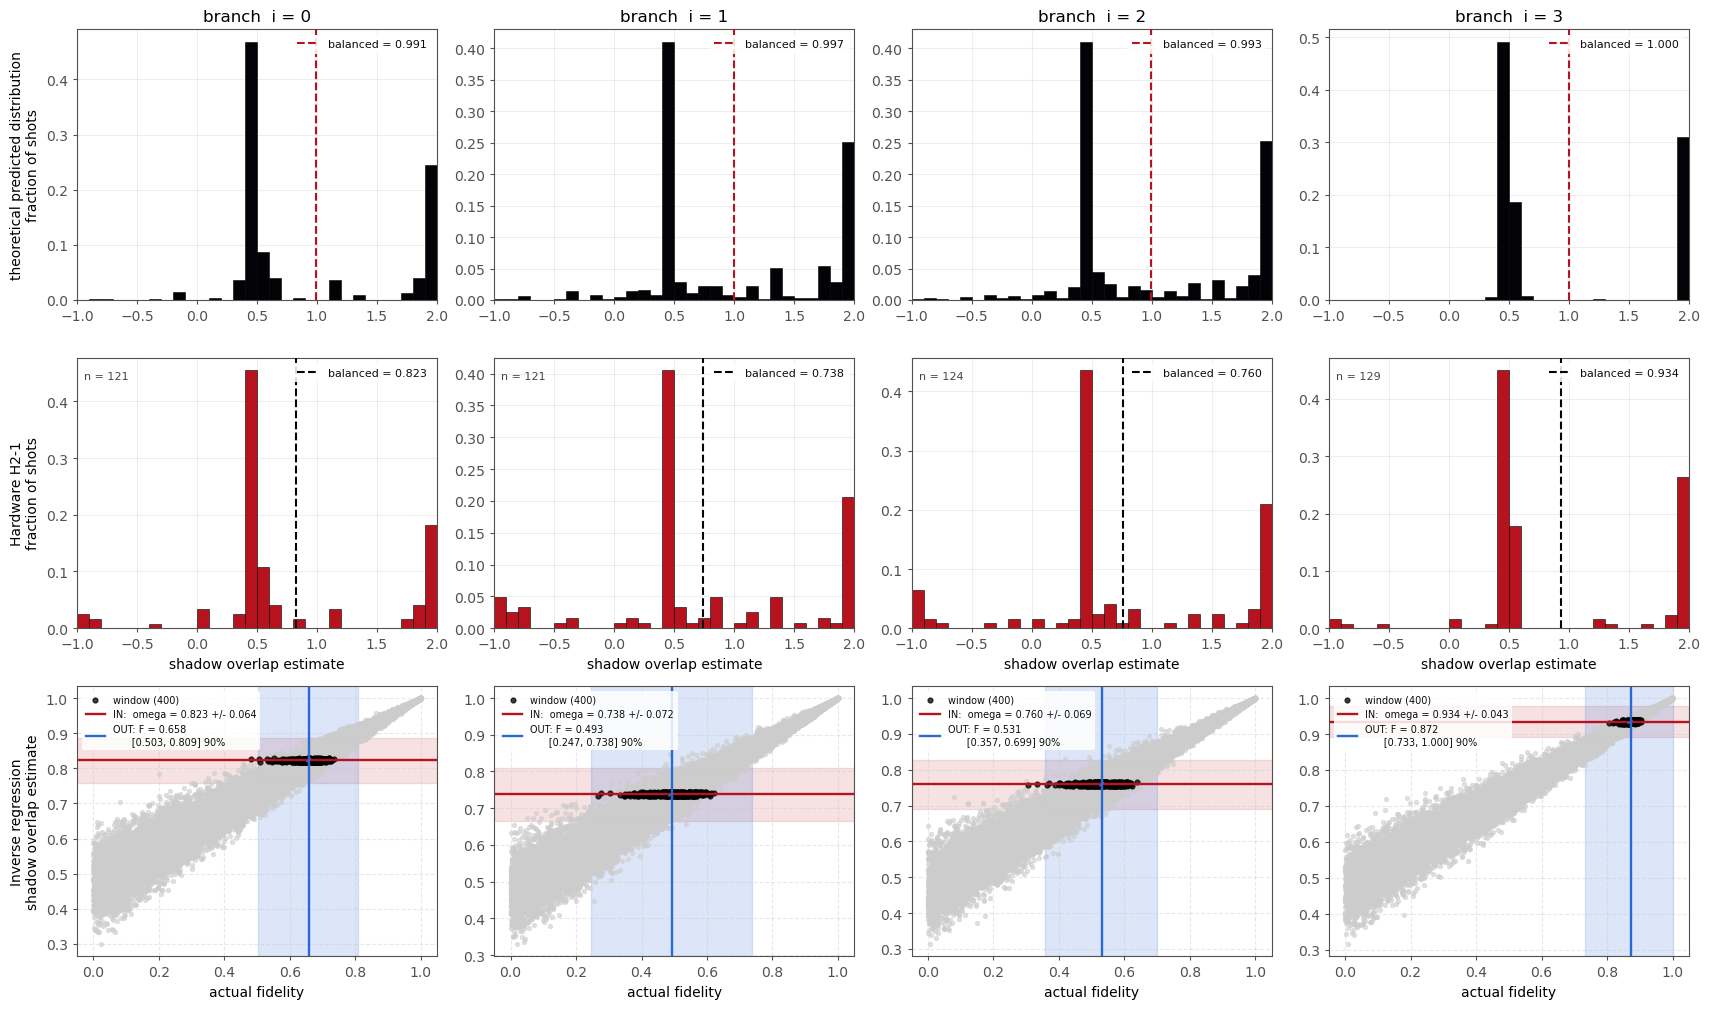

                           branch 0            branch 1            branch 2            branch 3           pooled
theoretical predicted distribution+0.991+/-0.002(24200)  +0.997+/-0.003(24200)  +0.993+/-0.003(24800)  +1.000+/-0.000(25800)   +0.9880+/-0.0012
Hardware H2-1         +0.823+/-0.064( 121)  +0.738+/-0.072( 121)  +0.760+/-0.069( 124)  +0.934+/-0.043( 129)   +0.8114+/-0.0315

 branch        measured omega        F      90% interval   width   dF/dw
      0       0.823 +/- 0.064    0.658   [0.503, 0.809]   0.306    1.32
      1       0.738 +/- 0.072    0.493   [0.247, 0.738]   0.491    1.91
      2       0.760 +/- 0.069    0.531   [0.357, 0.699]   0.342    1.31
      3       0.934 +/- 0.043    0.872   [0.733, 1.000]   0.267    1.92


In [5]:
# SOURCE: ShadowOverlapMultiregister.ipynb, cell 62 (helper functions: omega/compute_local_overlap)
#         + cell 70 (the plot itself, "# ==== STORAGE-REGISTER SHADOW OVERLAP, PER INDEX BRANCH ====").
# Reads the already-processed per-branch shot store and calibration curve off disk:
#   shadow_branch_hw.pkl              <- hardware X/Y/Z shots, keyed and branch-resolved
#   shadow_vs_fidelity_rows_orth.npz  <- the noiseless calibration curve (omega vs. fidelity), 3000 pts/row
#   mre_target_data.npz               <- the 4 target chunks |psi_i> (ideal state, for the noiseless check row)
# This is the cell that produced the raw numbers in Table I of the paper and saves "hardware_results_final.pdf".
# If you take new hardware shots, re-run the ShadowOverlapMultiregister.ipynb pipeline to refresh
# shadow_branch_hw.pkl, then just re-run this cell -- nothing else here needs to change.
# No chart title (caption lives in LaTeX) -- "branch i = ..." column tags are kept, they're
# structural facet labels (like the (a)/(b) tags elsewhere), not a redundant descriptive title.
# n = shot count is shown only on the Hardware row (a real, meaningful number); the "theoretical
# predicted distribution" row is a Monte-Carlo resampling whose size is an arbitrary parameter
# (SIM_REPS), not a physically meaningful shot count, so it carries no n label.
import random
import numpy as np
import matplotlib.pyplot as plt
import pickle

BASE = os.getcwd()
PAULIS = ["X", "Y", "Z"]
chunks = list(np.load(f"{BASE}/mre_target_data.npz")["chunks"])

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

NBINS = 30
S_QUBITS, N_S, M_BRANCH = tuple(range(5)), 5, 4
BR_STORE  = f"{BASE}/shadow_branch_hw.pkl"
ROWS_FILE = f"{BASE}/shadow_vs_fidelity_rows_orth.npz"
Y_VALUE, Z_ASSIGN_SEED, SIM_SEED, SIM_REPS = 0.5, 11, 2026, 200
CONF, K_NEIGHBOURS, USE, N_MC, MC_SEED = 0.90, 400, "exact", 200_000, 0
NO_SUPPORT_TOL = 1e-12

CHUNKS = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in chunks]
assert len(CHUNKS) == M_BRANCH and len(CHUNKS[0]) == 2 ** N_S

def rotated_outcome_to_zket(outcome, pauli):
    if pauli == "Z":
        return np.array([1, 0], dtype=complex) if outcome == 0 else np.array([0, 1], dtype=complex)
    if pauli == "X":
        return np.array([1, 1], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    if pauli == "Y":
        return np.array([1, 1j], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    raise ValueError(f"Pauli must be X, Y or Z, got {pauli!r}")

def compute_local_overlap(cond, outcome, P):
    """omega = <phi| (3|s><s| - I) |phi>  for a single-qubit conditional state."""
    s = rotated_outcome_to_zket(outcome, P)
    O3 = 3 * np.outer(s, s.conj()) - np.eye(2, dtype=complex)
    return np.vdot(np.asarray(cond, dtype=complex), O3 @ np.asarray(cond, dtype=complex)).real

_no_support = {"n": 0}
def omega(chunk, sb, q, p, tol=NO_SUPPORT_TOL):
    """One shadow-overlap estimate against a 32-amplitude chunk.
    The no-support guard MUST be a tolerance, not `== 0`: the ideally-vanishing
    amplitudes are stored as ~1e-16, never exactly zero."""
    pos = N_S - 1 - q
    z, o = sb[:pos] + "0" + sb[pos+1:], sb[:pos] + "1" + sb[pos+1:]
    v = np.array([chunk[int(z, 2)], chunk[int(o, 2)]], dtype=complex)
    nv = np.linalg.norm(v)
    if nv < tol:
        _no_support["n"] += 1
        return 0.0
    return compute_local_overlap(v / nv, int(sb[pos]), PAULIS[p])

def storage_shots(store, seed=Z_ASSIGN_SEED):
    """-> [(s_bits, branch, target_qubit, pauli)] for every usable shot.
    X: the qubit the rotation landed on. Z: the whole bank, each shot assigned one S
    qubit, never reused. Y: one per Z shot in the same branch (analytic, see Appendix E)."""
    recs = []
    for (q, p), d in store["xy"].items():
        if p == 1:
            continue                       # measured Y superseded by the analytic stratum
        for k, c in d.items():
            i, sb = k.split(":")
            recs += [(sb, int(i), q, p)] * c
    zs = [(k.split(":")[1], int(k.split(":")[0]))
          for k, c in store["z_pool"].items() for _ in range(c)]
    random.Random(seed).shuffle(zs)
    recs += [(sb, i, S_QUBITS[j % N_S], 2) for j, (sb, i) in enumerate(zs)]
    recs += [(sb, i, S_QUBITS[j % N_S], 1) for j, (sb, i) in enumerate(zs)]
    return recs

def measured_y(store):
    """The Y shots actually on file -- used only as a null test that omega == 0.5."""
    return [(k.split(":")[1], int(k.split(":")[0]), q)
            for (q, p), d in store["xy"].items() if p == 1
            for k, c in d.items() for _ in range(c)]

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)
def _rot_probs(vec, q, p):
    if p == 2:
        return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q)
    b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def sim_like(recs, reps=SIM_REPS, seed=SIM_SEED):
    """Noiseless reference matched cell-for-cell to `recs`: same (branch, qubit,
    Pauli) design, only the outcome bits resampled from the ideal chunk."""
    rng, cdfs, out = np.random.default_rng(seed), {}, []
    for _, i, q, p in recs:
        if (i, q, p) not in cdfs:
            cdfs[(i, q, p)] = np.cumsum(_rot_probs(CHUNKS[i], q, p))
        cdf = cdfs[(i, q, p)]
        idx = np.minimum(np.searchsorted(cdf, rng.random(reps)), len(cdf) - 1)
        out += [(np.binary_repr(int(j), width=N_S), i, q, p) for j in idx]
    return out

def evaluate(recs):
    _no_support["n"] = 0
    est = np.array([omega(CHUNKS[i], sb, q, p) for sb, i, q, p in recs])
    if _no_support["n"]:
        print(f"  note: {_no_support['n']} of {len(recs)} shots landed outside the ideal "
              f"support and were scored omega = 0")
    return est, np.array([i for _, i, _, _ in recs]), np.array([p for *_, p in recs])

def pauli_var(est, pau):
    return {p: float(est[pau == p].var(ddof=1)) for p in range(3) if (pau == p).sum() > 1}

def balanced(est, pau, var_ref=None):
    """Uniform-design (X,Y,Z) mean and its SE -- Y is exactly 0.5 with zero variance
    for a real target, so X and Z alone set the SE."""
    ms, vs = [], []
    for p in range(3):
        v = est[pau == p]
        if p == 1:
            ms.append(Y_VALUE); vs.append(0.0); continue
        if len(v) == 0:
            return float("nan"), float("nan")
        ms.append(v.mean())
        s2 = v.var(ddof=1) if len(v) > 1 else (var_ref or {}).get(p, np.nan)
        vs.append(s2 / len(v))
    return float(np.mean(ms)), float(np.sqrt(np.nansum(vs)) / 3)

def invert(F, w, omega_star, k):
    """Fit F = a + b*(omega - omega*) over the k trials nearest omega*."""
    sel = np.argsort(np.abs(w - omega_star))[:min(k, len(w))]
    ww, ff = w[sel] - omega_star, F[sel]
    b, a = np.polyfit(ww, ff, 1)
    resid = ff - (a + b * ww)
    return dict(a=a, b=b, resid=resid, sd=resid.std(ddof=2), sel=sel,
                lo=w[sel].min(), hi=w[sel].max(), n=len(sel))

def predict(fit, omega_star, omega_se, conf, rng, n=N_MC):
    draws = rng.normal(omega_star, omega_se, n) if omega_se else np.full(n, omega_star)
    vals = fit["a"] + fit["b"] * (draws - omega_star) + rng.choice(fit["resid"], n)
    lo, hi = np.percentile(vals, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return float(np.clip(lo, 0, 1)), float(np.clip(hi, 0, 1))

# A perfect state gives a balanced mean of 1.000 in EVERY cell, so the "theoretical predicted
# distribution" row is a check that this pipeline reproduces what theory demands, not a calibration.
with open(BR_STORE, "rb") as f:
    hw_recs = storage_shots(pickle.load(f))
rows = [("theoretical predicted distribution", BLACK, RED,  sim_like(hw_recs), False),
        ("Hardware H2-1",                      RED,   BLACK, hw_recs,          True)]

data = []
for label, fill, meanc, recs, show_n in rows:
    est, br, pau = evaluate(recs)
    data.append((label, fill, meanc, est, br, pau, pauli_var(est, pau), show_n))

with np.load(ROWS_FILE) as _z:
    z = {k: _z[k] for k in _z.files}

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42}):
    edges = np.linspace(min(d[3].min() for d in data), max(d[3].max() for d in data), NBINS + 1)
    fig, axes = plt.subplots(3, M_BRANCH, figsize=(4.3 * M_BRANCH, 3.4 * 3), squeeze=False)
    for r, (label, fill, meanc, est, br, pau, vref, show_n) in enumerate(data):
        for i in range(M_BRANCH):
            ax, v, p = axes[r, i], est[br == i], pau[br == i]
            if len(v):
                ax.hist(v, bins=edges, weights=np.full(len(v), 1 / len(v)),
                        color=fill, edgecolor="black", lw=0.4, zorder=2)
                m, s = balanced(v, p, vref)
                ax.axvline(m, color=meanc, ls="--", lw=1.5, zorder=3,
                           label=f"balanced = {m:.3f}")
                style_legend(ax, fontsize=8, loc="upper right")
                if show_n:
                    ax.text(0.02, 0.95, f"n = {len(v)}", transform=ax.transAxes,
                            va="top", fontsize=8, color="#444444")
            ax.set_xlim(edges[0], edges[-1]); ax.grid(alpha=0.3, zorder=0, color=GRID)
            tidy(ax)
            if r == 0: ax.set_title(f"branch  i = {i}", fontsize=12)
            else: ax.set_xlabel("shadow overlap estimate")
        axes[r, 0].set_ylabel(f"{label}\nfraction of shots", fontsize=10)

    # ---- row 3: the fidelity each measured omega implies (inverse regression, App. G) ----
    _, _, _, est, br, pau, vref, _ = data[1]
    rng, results = np.random.default_rng(MC_SEED), {}
    for i in range(M_BRANCH):
        ax = axes[2, i]
        omega_star, omega_se = balanced(est[br == i], pau[br == i], vref)
        w, F = z[f"row{i}_{USE}"], z[f"row{i}_fid"]
        if omega_star != omega_star:
            ax.text(0.5, 0.5, "no estimate yet", transform=ax.transAxes, ha="center"); continue
        if not (w.min() <= omega_star <= w.max()):
            print(f"WARNING branch {i}: omega* = {omega_star:.3f} is outside the simulated "
                  f"range [{w.min():.3f}, {w.max():.3f}] -- extrapolating")
        fit = invert(F, w, omega_star, K_NEIGHBOURS)
        lo, hi = predict(fit, omega_star, omega_se, CONF, rng)
        results[i] = (omega_star, omega_se, fit, lo, hi)
        inside = np.zeros(len(w), bool); inside[fit["sel"]] = True
        ax.scatter(F[~inside], w[~inside], color="#cccccc", alpha=0.55, s=8)
        ax.scatter(F[inside],  w[inside],  color="black",   alpha=0.75, s=12,
                   label=f"window ({fit['n']})")
        ax.axhspan(omega_star - omega_se, omega_star + omega_se, color=RED, alpha=0.12, zorder=0)
        ax.axhline(omega_star, color=RED, lw=1.7,
                   label=f"IN:  omega = {omega_star:.3f} +/- {omega_se:.3f}")
        ax.axvspan(lo, hi, color=BLUE, alpha=0.16, zorder=0)
        ax.axvline(fit["a"], color=BLUE, lw=1.7,
                   label=f"OUT: F = {fit['a']:.3f}\n      [{lo:.3f}, {hi:.3f}] {CONF:.0%}")
        xs = np.linspace(fit["lo"], fit["hi"], 50)
        ax.plot(fit["a"] + fit["b"] * (xs - omega_star), xs, color=BLUE, ls="--", lw=1.2)
        ax.set_xlabel("actual fidelity"); ax.grid(True, ls="--", alpha=0.4, color=GRID)
        tidy(ax)
        style_legend(ax, fontsize=7, loc="upper left")
    axes[2, 0].set_ylabel("Inverse regression\nshadow overlap estimate", fontsize=10)

    plt.tight_layout()
    fig.savefig(f"{BASE}/hardware_results_final.pdf", bbox_inches="tight")
    plt.show()

nx = int((data[1][5] == 0).sum()); nz = int((data[1][5] == 2).sum())
if nx < nz:
    print(f"PROVISIONAL -- {nx} X shots against {nz} Z, {nz-nx} still to run")

print(f"{'':<22s}" + "  ".join(f"branch {i}".center(18) for i in range(M_BRANCH)) + "      pooled")
for label, _, _, est, br, pau, vref, _ in data:
    cells_ = []
    for i in range(M_BRANCH):
        m, s = balanced(est[br == i], pau[br == i], vref)
        cells_.append((f"{m:+.3f}+/-{s:.3f}({(br==i).sum():>4d})" if m == m else "-").center(18))
    m, s = balanced(est, pau, vref)
    print(f"{label:<22s}" + "  ".join(cells_) + f"   {m:+.4f}+/-{s:.4f}")

print(f"\n{'branch':>7}{'measured omega':>22}{'F':>9}{'  '+f'{CONF:.0%} interval':>18}"
      f"{'width':>8}{'dF/dw':>8}")
for i in sorted(results):
    om, se, fit, lo, hi = results[i]
    print(f"{i:>7}{f'{om:.3f} +/- {se:.3f}':>22}{fit['a']:>9.3f}   "
          f"[{lo:.3f}, {hi:.3f}]{hi-lo:>8.3f}{fit['b']:>8.2f}")


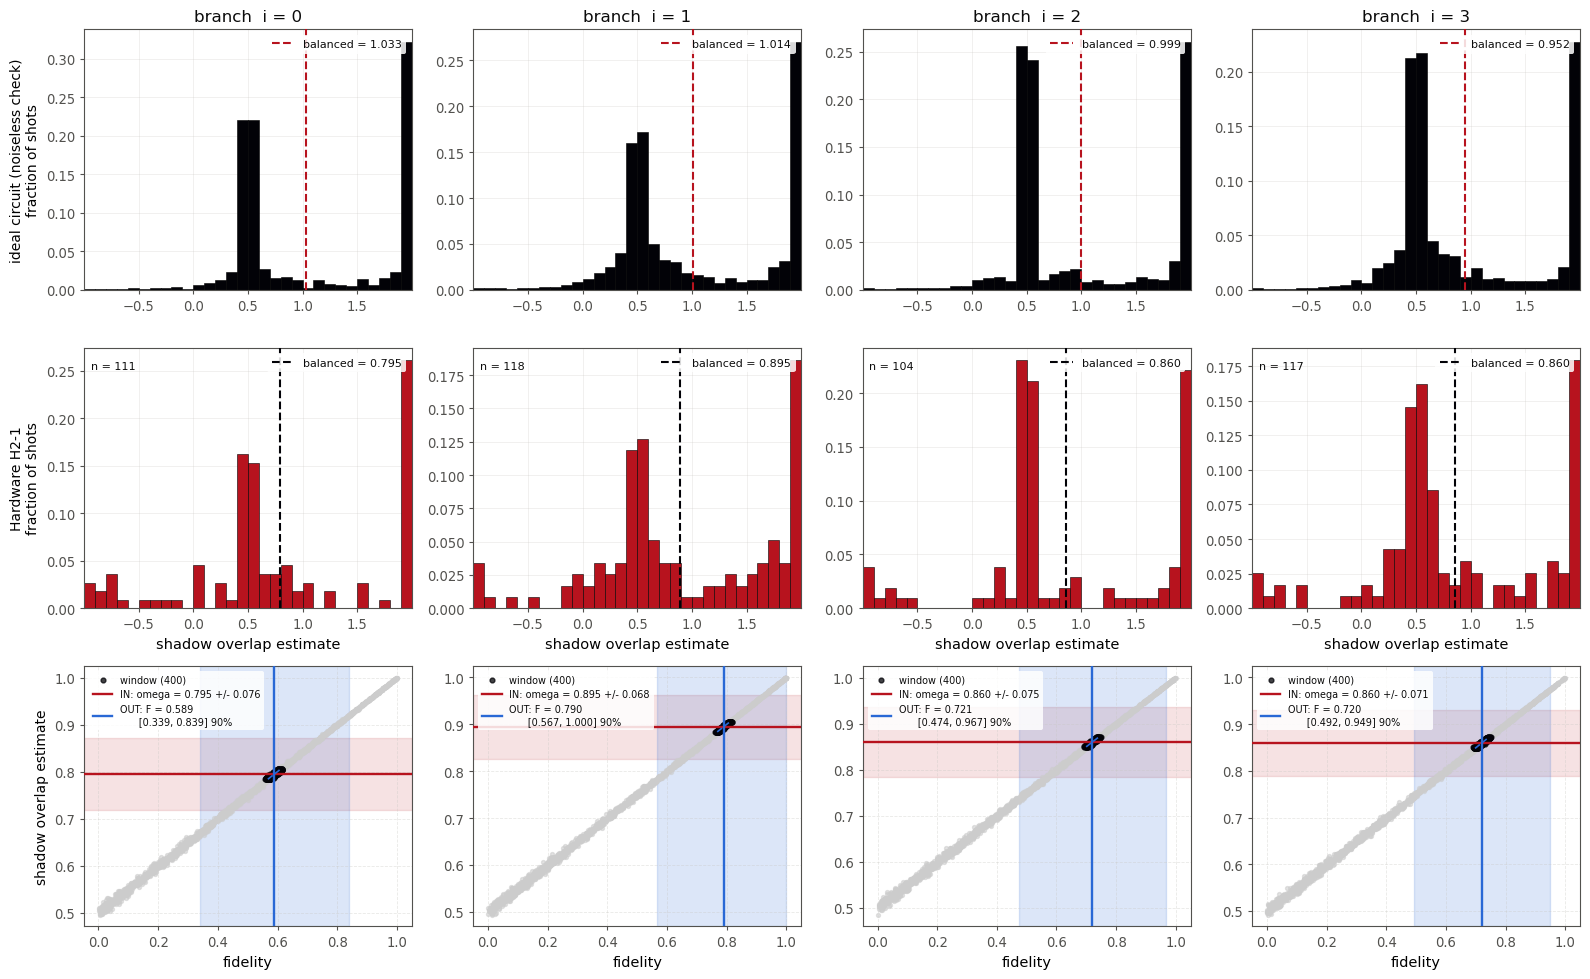

calibration points per branch: 9000   drawn: 1500 + 400 window (rasterised)
branch 0: omega 0.795 +/- 0.076  ->  F = 0.589  [0.339, 0.839] 90%  (vs ideal circuit output)
branch 1: omega 0.895 +/- 0.068  ->  F = 0.790  [0.567, 1.000] 90%  (vs ideal circuit output)
branch 2: omega 0.860 +/- 0.075  ->  F = 0.721  [0.474, 0.967] 90%  (vs ideal circuit output)
branch 3: omega 0.860 +/- 0.071  ->  F = 0.720  [0.492, 0.949] 90%  (vs ideal circuit output)


In [89]:
# SOURCE: ShadowOverlapMultiregister.ipynb, cell 78 ("STORAGE-REGISTER SHADOW OVERLAP, PER
#         INDEX BRANCH (4x1024_L1_mid)"), restyled to this notebook's report style and made
#         light enough to open quickly.
#
# This is the UPSCALED (4 x 1024, 53-qubit) hardware run -- Fig. 5 and Table I of the paper.
# The other Fig. 5 cell in this notebook is the 4x32 / 28-qubit run; both are kept.
#
# WHY IT USED TO BE SLOW: the bottom row drew the full calibration cloud as vector points --
# 9000 per branch x 4 branches = 36,000 individual PDF path objects, which is what makes the
# viewer crawl. Two fixes, both display-only:
#   SHOW_N        -- draw a random subsample of the out-of-window cloud (the FIT still uses
#                    every one of the 9000 points; nothing numerical changes, see below).
#   rasterized    -- the scatter layers are rasterised at SCATTER_DPI, so they become one
#                    small image per panel instead of thousands of paths. Text, axes, lines
#                    and the regression fit stay vector/selectable.
# The window points (the K_NEIGHBOURS actually used by the local fit) are NEVER subsampled --
# they are the evidence for the quoted number, so they are all drawn.
#
# Reads off disk, nothing upstream needs re-running:
#   shadow_branch_hw_4x1024_L1_mid.pkl                      <- branch-resolved hardware shots
#   shadow_vs_fidelity_rows_4x1024_L1_mid_vs_ideal.npz      <- calibration curve, 9000 pts/branch
#   mre_prep_circuits_4x1024_L1_mid.qpy                     <- the per-branch IDEAL reference
#
# The reference is IDEAL[i] = what the circuit itself prepares for branch i, NOT the raw target
# row, so the fidelity reported is hardware degradation with the deliberately-lossy 1-layer SSO
# encoding error factored out. X, Y and Z are all genuinely measured here (no analytic-Y
# shortcut, since IDEAL is not real-valued the way the raw rows were).
import os, random, pickle
import numpy as np
import matplotlib.pyplot as plt
from qiskit import qpy
from qiskit.quantum_info import Statevector

BASE = os.getcwd()
TAG  = "4x1024_L1_mid"

SHOW_N      = 1500     # out-of-window calibration points DRAWN per panel (of 9000). None = all.
SCATTER_DPI = 220      # rasterisation dpi for the point clouds
PLOT_SEED   = 0        # which subsample you get; fixed so the figure is reproducible

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

PAULIS = ["X", "Y", "Z"]
NBINS  = 30
BR_STORE  = os.path.join(BASE, f"shadow_branch_hw_{TAG}.pkl")
ROWS_FILE = os.path.join(BASE, f"shadow_vs_fidelity_rows_{TAG}_vs_ideal.npz")
Z_ASSIGN_SEED, SIM_SEED, SIM_REPS = 11, 2026, 200
CONF, K_NEIGHBOURS, USE, N_MC, MC_SEED = 0.90, 400, "exact", 200_000, 0
NO_SUPPORT_TOL = 1e-12

prep_circuits = qpy.load(open(os.path.join(BASE, f"mre_prep_circuits_{TAG}.qpy"), "rb"))
IDEAL   = [np.asarray(Statevector(c)) for c in prep_circuits]
CHUNKS  = [np.asarray(c, dtype=complex) / np.linalg.norm(c) for c in IDEAL]
N_S, M_BRANCH = prep_circuits[0].num_qubits, len(prep_circuits)
S_QUBITS = tuple(range(N_S))
assert len(CHUNKS[0]) == 2 ** N_S

def rotated_outcome_to_zket(outcome, pauli):
    if pauli == "Z":
        return np.array([1, 0], dtype=complex) if outcome == 0 else np.array([0, 1], dtype=complex)
    if pauli == "X":
        return np.array([1, 1], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1], dtype=complex)/np.sqrt(2)
    if pauli == "Y":
        return np.array([1, 1j], dtype=complex)/np.sqrt(2) if outcome == 0 else np.array([1, -1j], dtype=complex)/np.sqrt(2)
    raise ValueError(f"Pauli must be X, Y or Z, got {pauli!r}")

def compute_local_overlap(cond, outcome, P):
    """omega = <phi| (3|s><s| - I) |phi>  for a single-qubit conditional state."""
    s = rotated_outcome_to_zket(outcome, P)
    O3 = 3 * np.outer(s, s.conj()) - np.eye(2, dtype=complex)
    return np.vdot(np.asarray(cond, dtype=complex), O3 @ np.asarray(cond, dtype=complex)).real

_no_support = {"n": 0}
def omega(chunk, sb, q, p, tol=NO_SUPPORT_TOL):
    """One shadow-overlap estimate. The no-support guard MUST be a tolerance, not `== 0`:
    ideally-vanishing amplitudes are stored as ~1e-16, never exactly zero."""
    pos = N_S - 1 - q
    z, o = sb[:pos] + "0" + sb[pos+1:], sb[:pos] + "1" + sb[pos+1:]
    v = np.array([chunk[int(z, 2)], chunk[int(o, 2)]], dtype=complex)
    nv = np.linalg.norm(v)
    if nv < tol:
        _no_support["n"] += 1; return 0.0
    return compute_local_overlap(v / nv, int(sb[pos]), PAULIS[p])

def storage_shots(store, seed=Z_ASSIGN_SEED):
    """X and Y are both real hardware shots here; Z is the shared prep/ancilla-targeted bank."""
    recs = []
    for (q, p), d in store["xy"].items():
        for k, c in d.items():
            i, sb = k.split(":")
            recs += [(sb, int(i), q, p)] * c
    zs = [(k.split(":")[1], int(k.split(":")[0])) for k, c in store["z_pool"].items() for _ in range(c)]
    random.Random(seed).shuffle(zs)
    recs += [(sb, i, S_QUBITS[j % N_S], 2) for j, (sb, i) in enumerate(zs)]
    return recs

_H, _Sdg = np.array([[1, 1], [1, -1]]) / np.sqrt(2), np.diag([1, -1j]).astype(complex)
def _rot_probs(vec, q, p):
    if p == 2: return np.abs(vec) ** 2
    U = _H if p == 0 else _H @ _Sdg
    v3 = vec.reshape(-1, 2, 2 ** q); b0, b1 = v3[:, 0, :], v3[:, 1, :]
    out = np.empty_like(v3)
    out[:, 0, :], out[:, 1, :] = U[0,0]*b0 + U[0,1]*b1, U[1,0]*b0 + U[1,1]*b1
    return np.abs(out.reshape(-1)) ** 2

def sim_like(recs, reps=SIM_REPS, seed=SIM_SEED):
    """Noiseless reference matched cell-for-cell to `recs`: same (branch, qubit, Pauli)
    design, only the outcome bits resampled from the ideal state."""
    rng, cdfs, out = np.random.default_rng(seed), {}, []
    for _, i, q, p in recs:
        if (i, q, p) not in cdfs:
            cdfs[(i, q, p)] = np.cumsum(_rot_probs(CHUNKS[i], q, p))
        cdf = cdfs[(i, q, p)]
        idx = np.minimum(np.searchsorted(cdf, rng.random(reps)), len(cdf) - 1)
        out += [(np.binary_repr(int(j), width=N_S), i, q, p) for j in idx]
    return out

def evaluate(recs):
    _no_support["n"] = 0
    est = np.array([omega(CHUNKS[i], sb, q, p) for sb, i, q, p in recs])
    return est, np.array([i for _, i, _, _ in recs]), np.array([p for *_, p in recs])

def pauli_var(est, pau):
    return {p: float(est[pau == p].var(ddof=1)) for p in range(3) if (pau == p).sum() > 1}

def balanced(est, pau, var_ref=None):
    """Uniform-design (X,Y,Z) mean and its SE -- all three strata genuinely measured."""
    ms, vs = [], []
    for p in range(3):
        v = est[pau == p]
        if len(v) == 0: return float("nan"), float("nan")
        ms.append(v.mean())
        s2 = v.var(ddof=1) if len(v) > 1 else (var_ref or {}).get(p, np.nan)
        vs.append(s2 / len(v))
    return float(np.mean(ms)), float(np.sqrt(np.nansum(vs)) / 3)

def invert(F, w, omega_star, k):
    sel = np.argsort(np.abs(w - omega_star))[:min(k, len(w))]
    ww, ff = w[sel] - omega_star, F[sel]
    b, a = np.polyfit(ww, ff, 1)
    return dict(a=a, b=b, resid=ff - (a + b * ww), sel=sel,
                lo=w[sel].min(), hi=w[sel].max(), n=len(sel))

def predict(fit, omega_star, omega_se, conf, rng, n=N_MC):
    draws = rng.normal(omega_star, omega_se, n) if omega_se else np.full(n, omega_star)
    vals  = fit["a"] + fit["b"] * (draws - omega_star) + rng.choice(fit["resid"], n)
    lo, hi = np.percentile(vals, [(1 - conf) / 2 * 100, (1 + conf) / 2 * 100])
    return float(np.clip(lo, 0, 1)), float(np.clip(hi, 0, 1))

with open(BR_STORE, "rb") as f:
    hw_recs = storage_shots(pickle.load(f))
rows = [("ideal circuit (noiseless check)", BLACK, RED,  sim_like(hw_recs)),
        ("Hardware H2-1",                   RED,   BLACK, hw_recs)]
data = []
for label, fill, meanc, recs in rows:
    est, br, pau = evaluate(recs)
    data.append((label, fill, meanc, est, br, pau, pauli_var(est, pau)))
with np.load(ROWS_FILE) as _z:
    z = {k: _z[k] for k in _z.files}

edges = np.linspace(min(d[3].min() for d in data), max(d[3].max() for d in data), NBINS + 1)

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 8}):
    fig, axes = plt.subplots(3, M_BRANCH, figsize=(4.0 * M_BRANCH, 3.3 * 3), squeeze=False)

    for r, (label, fill, meanc, est, br, pau, vref) in enumerate(data):
        for i in range(M_BRANCH):
            ax, v, p = axes[r, i], est[br == i], pau[br == i]
            if len(v):
                ax.hist(v, bins=edges, weights=np.full(len(v), 1 / len(v)),
                        color=fill, edgecolor="black", lw=0.4, zorder=2)
                m, s = balanced(v, p, vref)
                ax.axvline(m, color=meanc, ls="--", lw=1.5, zorder=3,
                           label=f"balanced = {m:.3f}")
                if label == "Hardware H2-1":
                    ax.text(0.02, 0.95, f"n = {len(v)}", transform=ax.transAxes,
                            va="top", fontsize=8, color=INK)
                style_legend(ax, loc="upper right")
            ax.set_xlim(edges[0], edges[-1])
            ax.grid(alpha=0.3, lw=0.6, color=GRID)
            if r == 0: ax.set_title(f"branch  i = {i}", fontsize=12, color=INK)
            else:      ax.set_xlabel("shadow overlap estimate")
            tidy(ax)
        axes[r, 0].set_ylabel(f"{label}\nfraction of shots", fontsize=10)

    _, _, _, est, br, pau, vref = data[1]
    rng, results = np.random.default_rng(MC_SEED), {}
    plot_rng = np.random.default_rng(PLOT_SEED)
    for i in range(M_BRANCH):
        ax = axes[2, i]
        omega_star, omega_se = balanced(est[br == i], pau[br == i], vref)
        w, F = z[f"row{i}_{USE}"], z[f"row{i}_fid"]
        if omega_star != omega_star:
            ax.text(0.5, 0.5, "no estimate yet", transform=ax.transAxes, ha="center"); continue

        fit = invert(F, w, omega_star, K_NEIGHBOURS)      # <- uses ALL 9000 points
        lo, hi = predict(fit, omega_star, omega_se, CONF, rng)
        results[i] = (omega_star, omega_se, fit, lo, hi)

        inside = np.zeros(len(w), bool); inside[fit["sel"]] = True
        out_idx = np.flatnonzero(~inside)
        if SHOW_N is not None and len(out_idx) > SHOW_N:    # DISPLAY ONLY -- fit unaffected
            out_idx = plot_rng.choice(out_idx, SHOW_N, replace=False)
        ax.scatter(F[out_idx], w[out_idx], color="#cccccc", alpha=0.55, s=8,
                   rasterized=True, zorder=1)
        ax.scatter(F[inside], w[inside], color=BLACK, alpha=0.75, s=12,
                   rasterized=True, zorder=2, label=f"window ({fit['n']})")

        ax.axhspan(omega_star - omega_se, omega_star + omega_se, color=RED, alpha=0.12, zorder=0)
        ax.axhline(omega_star, color=RED, lw=1.7, zorder=3,
                   label=f"IN: omega = {omega_star:.3f} +/- {omega_se:.3f}")
        ax.axvspan(lo, hi, color=BLUE, alpha=0.16, zorder=0)
        ax.axvline(fit["a"], color=BLUE, lw=1.7, zorder=3,
                   label=f"OUT: F = {fit['a']:.3f}\n      [{lo:.3f}, {hi:.3f}] {CONF:.0%}")
        xs = np.linspace(fit["lo"], fit["hi"], 50)
        ax.plot(fit["a"] + fit["b"] * (xs - omega_star), xs, color=BLUE, ls="--", lw=1.2, zorder=3)
        ax.set_xlabel("fidelity")
        ax.grid(True, ls="--", alpha=0.4, lw=0.6, color=GRID)
        style_legend(ax, loc="upper left", fontsize=7)
        tidy(ax)
    axes[2, 0].set_ylabel("shadow overlap estimate", fontsize=10)

    fig.tight_layout()
    fig.savefig(os.path.join(BASE, f"fig_hardware_{TAG}.pdf"),
                bbox_inches="tight", dpi=SCATTER_DPI)
    plt.show()

print(f"calibration points per branch: {len(z['row0_fid'])}   "
      f"drawn: {SHOW_N if SHOW_N else 'all'} + {K_NEIGHBOURS} window (rasterised)")
for i in sorted(results):
    om, se, fit, lo, hi = results[i]
    print(f"branch {i}: omega {om:.3f} +/- {se:.3f}  ->  F = {fit['a']:.3f}  "
          f"[{lo:.3f}, {hi:.3f}] {CONF:.0%}  (vs ideal circuit output)")


## Fig. 6 — Reweighting success probability vs. M, Haar-random chunks

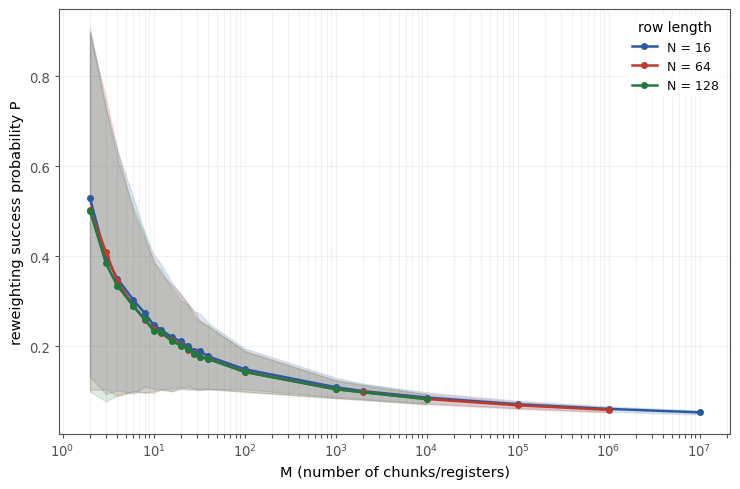


     N   M (largest tested)     P_mean      P_p10      P_p90
    16             10000000 5.2992e-02 4.8258e-02 5.7075e-02
    64              1000000 5.8703e-02 5.2906e-02 6.4016e-02
   128                10000 8.2335e-02 7.0767e-02 9.3462e-02


In [6]:
# SOURCE: "Reweighting Success Probability vs M N.ipynb", cell 1 (LINE_COLORS)
#         + cell 12 (runs/loads the sweep into sweep_success_prob_vs_M.csv)
#         + cell 13 (the plot itself).
# Reads the already-finished sweep off disk (1500 trials per (M, N) point, M up to 1e7):
#   sweep_success_prob_vs_M.csv
# To extend the grid (larger M, or a new N), go re-run the sweep in that notebook -- it
# appends to the same CSV and skips (M, N) points already done -- then just re-run this cell.
#
# No chart title (caption lives in LaTeX). These line colors encode a different variable
# (row length N) from the red/blue/black preconditioning comparison used in Figs. 3 & 4 above,
# so they keep their own categorical palette.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE = os.getcwd()

# ---- shared report style (identical block in every figure cell in this notebook) ----
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

RED, BLUE, GREEN, GREY, BLACK = '#c0392b', '#2c5aa0', '#1f7a3f', '#7f8c8d', '#111111'
LINE_COLORS = [BLUE, RED, GREEN, GREY, BLACK]   # fixed categorical order for multi-line plots

N_values_1 = [16, 64, 128]
N_TRIALS_1 = 1500          # trials/point used when sweep_success_prob_vs_M.csv was generated

df_M = pd.read_csv(os.path.join(BASE, "sweep_success_prob_vs_M.csv"))

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    fig, ax = plt.subplots(figsize=(7.5, 5))
    for N, color in zip(N_values_1, LINE_COLORS):
        sub = df_M[df_M.N == N].sort_values("M")
        ax.plot(sub.M, sub.P_mean, color=color, marker='o', ms=4, lw=1.8, label=f"N = {N}")
        ax.fill_between(sub.M, sub.P_p10, sub.P_p90, color=color, alpha=0.15)

    ax.set_xscale("log")
    ax.set_xlabel("M (number of chunks/registers)")
    ax.set_ylabel("reweighting success probability P")
    style_legend(ax, title="row length")
    ax.grid(alpha=0.25, which='both', color=GRID)
    tidy(ax)
    plt.tight_layout()
    fig.savefig(os.path.join(BASE, "sweep_P_vs_M.pdf"), bbox_inches="tight")
    fig.savefig(os.path.join(BASE, "sweep_P_vs_M.png"), dpi=130)
    plt.show()

print(f"\n{'N':>6s} {'M (largest tested)':>20s} {'P_mean':>10s} {'P_p10':>10s} {'P_p90':>10s}")
for N in N_values_1:
    sub = df_M[df_M.N == N].sort_values("M")
    last = sub.iloc[-1]
    print(f"{N:>6d} {int(last.M):>20d} {last.P_mean:>10.4e} {last.P_p10:>10.4e} {last.P_p90:>10.4e}")


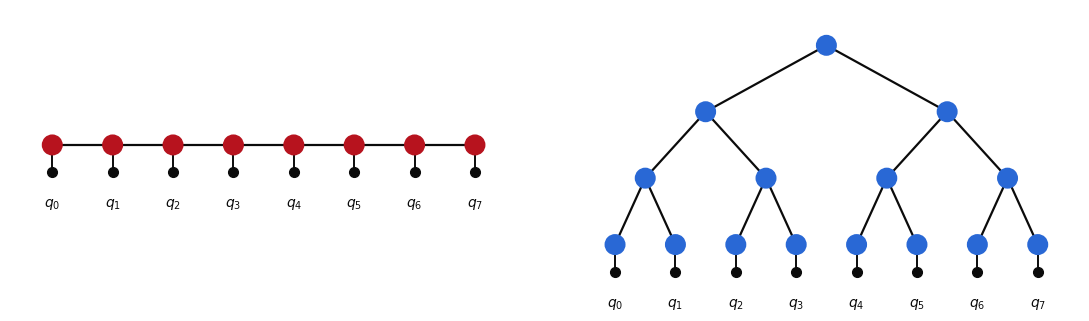

In [7]:
# Structural diagram: MPS vs TTN tensor-network topology for an 8-qubit register.
# Pure schematic (no data) -- same white background / RED-BLUE palette as the other
# report figures in this notebook, so it drops into the same slide deck cleanly.
# No panel labels here -- MPS/TTN captions live in the LaTeX caption.
import os
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle

BASE = os.getcwd()

INK, MUTED = "#0b0b0b", "#52514e"
RED, BLUE = "#b7131e", "#2968d5"
N_Q = 8

def draw_node(ax, xy, color, r=0.16, lw=1.2, z=3):
    ax.add_patch(Circle(xy, r, facecolor=color, edgecolor=color, lw=lw, zorder=z))

def draw_bond(ax, p, q, lw=1.6, z=1):
    ax.plot([p[0], q[0]], [p[1], q[1]], color=INK, lw=lw, zorder=z,
             solid_capstyle="round")

def draw_leg(ax, xy, length=0.45, z=1):
    x, y = xy
    ax.plot([x, x], [y, y - length], color=INK, lw=1.4, zorder=z,
             solid_capstyle="round")
    ax.plot(x, y - length, marker="o", ms=7, mfc=INK, mec=INK, zorder=z + 1)

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5}):
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.0, 4.4))
    fig.patch.set_facecolor("white")

    # ================= left: MPS chain =================
    axL.set_facecolor("white")
    xs = np.arange(N_Q, dtype=float)
    y0 = 0.0
    for i in range(N_Q - 1):
        draw_bond(axL, (xs[i], y0), (xs[i + 1], y0))
    for i in range(N_Q):
        draw_leg(axL, (xs[i], y0))
        draw_node(axL, (xs[i], y0), RED)
        axL.text(xs[i], y0 - 0.85, f"$q_{i}$", ha="center", va="top",
                 fontsize=10, color=INK, fontweight="medium")
    axL.set_xlim(-0.7, N_Q - 0.3); axL.set_ylim(-1.1, 0.6)

    # ================= right: TTN (balanced binary tree) =================
    axR.set_facecolor("white")
    levels = [xs.tolist()]
    while len(levels[-1]) > 1:
        prev = levels[-1]
        levels.append([(prev[i] + prev[i + 1]) / 2 for i in range(0, len(prev), 2)])
    ys = [0.0, 1.1, 2.2, 3.3][:len(levels)]

    for lvl in range(len(levels) - 1):
        xs_lo, xs_hi = levels[lvl], levels[lvl + 1]
        for i, xp in enumerate(xs_hi):
            for xc in (xs_lo[2 * i], xs_lo[2 * i + 1]):
                draw_bond(axR, (xc, ys[lvl]), (xp, ys[lvl + 1]))

    for i, x in enumerate(levels[0]):
        draw_leg(axR, (x, ys[0]))
        axR.text(x, ys[0] - 0.85, f"$q_{i}$", ha="center", va="top",
                 fontsize=10, color=INK, fontweight="medium")
    for lvl, xs_l in enumerate(levels):
        for x in xs_l:
            draw_node(axR, (x, ys[lvl]), BLUE)

    axR.set_xlim(-0.7, N_Q - 0.3); axR.set_ylim(-1.1, ys[-1] + 0.6)

    for ax in (axL, axR):
        ax.set_aspect("equal"); ax.axis("off")

    fig.tight_layout(w_pad=4.0)
    fig.savefig(os.path.join(BASE, "mpsandttn.pdf"), bbox_inches="tight",
               facecolor="white")
    plt.show()


  [R75x4_orig] 128 rows at depth 200
  [R75x4_precond_L10] 128 rows at depth 160
  [direct] 200 layers


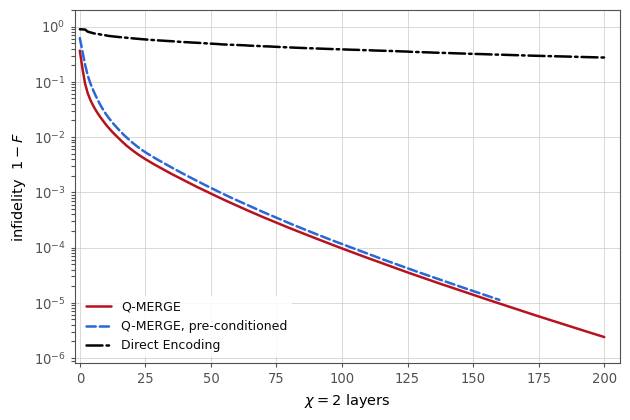

Q-MERGE                      depth 200   1-F = 2.4008e-06
Q-MERGE, pre-conditioned     depth 160   1-F = 1.1308e-05
Direct Encoding              depth 200   1-F = 2.7636e-01


In [27]:
#TEMPORY CELL FOR UPDATES
# ===== STANDALONE PREVIEW of panel (a) -- paste into a NEW notebook, run on its own =====
# Reads only files on disk, so it is safe to run in a second kernel while the batch cells
# are still going in the main notebook. No SSO setup cell, no quimb, no A0 needed.
# Any curve whose run hasn't started (or hasn't got all 128 rows yet) is simply left off.
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from skimage.transform import resize

BASE  = os.getcwd()
TAG, FULL_M, FULL_N = "R75x4", 128, 1024
RUN_ORIG, RUN_PRECOND = f"{TAG}_orig", f"{TAG}_precond_L10"
XMAX = 400                      # x-axis cap; raise if you push the sweeps deeper

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"

def tidy(ax):                   # full box, matching the notebook's bordered style
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

# raw-data sigma, only used as a fallback if a run predates sigma.npy
_Y = resize(pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None).to_numpy(),
            (FULL_N, FULL_M), anti_aliasing=True)
_Y = _Y / np.linalg.norm(_Y)
_rn = np.linalg.norm(_Y.T, axis=1)
sigma_raw = _rn / np.linalg.norm(_rn)

def combined_infid(run_name):
    """1 - F per layer, F = (sum_i sigma_i^2 sqrt(F_i))^2, at the depth ALL rows reached."""
    folder = os.path.join(BASE, "SSO results", f"row_sweep_{run_name}")
    path   = os.path.join(folder, "row_fids.json")
    if not os.path.exists(path):
        print(f"  [{run_name}] not started"); return None
    sig_path = os.path.join(folder, "sigma.npy")
    sig = np.load(sig_path) if os.path.exists(sig_path) else sigma_raw
    with open(path) as f:
        d = json.load(f)
    have = [i for i in range(FULL_M) if str(i) in d]
    if len(have) < FULL_M:
        print(f"  [{run_name}] only {len(have)}/{FULL_M} rows yet -- omitted"); return None
    fids = [np.array(d[str(i)]["chi"]["2"]["chi_fids"], float) for i in range(FULL_M)]
    L    = min(len(x) for x in fids)
    F    = np.clip(np.array([x[:L] for x in fids]), 0.0, 1.0)
    amp  = (sig[:, None] ** 2 * np.sqrt(F)).sum(axis=0)
    print(f"  [{run_name}] {FULL_M} rows at depth {L-1}")
    return np.clip(1.0 - np.clip(amp ** 2, 0.0, 1.0), 1e-16, None)

infid_A, infid_B = combined_infid(RUN_ORIG), combined_infid(RUN_PRECOND)
infid_C = None
for _c in (os.path.join(BASE, "SSO results", f"fullstate_{TAG}", "checkpoint.npz"),
           os.path.join(BASE, "SSO results", f"fullstate_{TAG}", "checkpoint.npz")):
    if os.path.exists(_c):
        with np.load(_c) as ck:
            infid_C = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)
        print(f"  [direct] {len(infid_C)-1} layers"); break
else:
    print("  [direct] not started")

SERIES = [(y, c, ls, lab) for y, c, ls, lab in
          ((infid_A, RED, "-", "Q-MERGE"),
           (infid_B, BLUE, "--", "Q-MERGE, pre-conditioned"),
           (infid_C, BLACK, "-.", "Direct Encoding")) if y is not None]
assert SERIES, "nothing on disk yet"

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    fig, ax = plt.subplots(figsize=(6.4, 4.3))
    ax.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
    ENDS = []
    for y, c, ls, lab in SERIES:
        keep = np.flatnonzero(y > 1e-16)
        k = min((keep[-1] + 1) if keep.size else len(y), XMAX + 1)
        ax.semilogy(np.arange(k), y[:k], ls=ls, lw=1.8, color=c, label=lab,
                    solid_capstyle="round", dash_capstyle="round")
        ENDS.append((k - 1, y[k - 1]))
    ax.set_xlabel(r"$\chi=2$ layers"); ax.set_ylabel(r"infidelity  $1-F$")
    ax.set_ylim(min(e[1] for e in ENDS) / 3.0, 2.0)
    ax.set_xlim(-2, max(e[0] for e in ENDS) * 1.03)
    ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=20))
    ax.yaxis.set_minor_formatter(NullFormatter())
    ax.legend(frameon=True, facecolor="white", edgecolor="none", framealpha=0.85, labelcolor=INK,
              loc="lower left")
    tidy(ax)
    fig.tight_layout()
    fig.savefig(os.path.join(BASE, f"fig_{TAG}_infidelity_preview.pdf"), bbox_inches="tight")
    plt.show()

for (y, _, _, lab), (k, _) in zip(SERIES, ENDS):
    print(f"{lab:<28s} depth {k:>3d}   1-F = {y[k]:.4e}")


## Diagrams for updated report

file                             depths  best L   P@bestL  IPR/floor
v_R75x4_M32_incr.pkl              1..30      27    0.3243      1.489


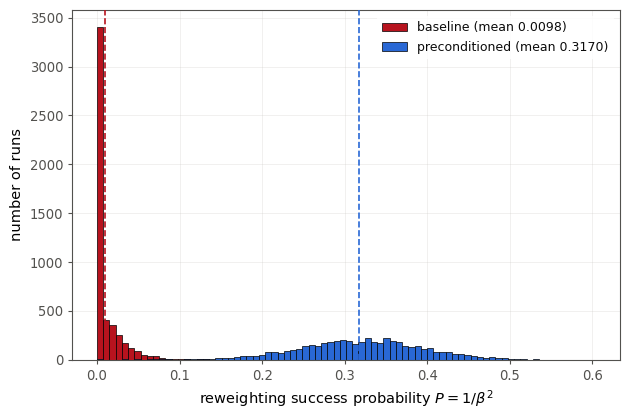

------------------------------------------------------------------------
source      v_R75x4_M32_incr.pkl, layer 3 (pinned)
baseline    mean P = 0.0098 (converged, 100k shots)   median 0.00033   histogram from 5000 shots, whose own mean is 0.0102 +/- 0.0003
 3 layers   mean P = 0.3170 +/- 0.0011   median 0.32060   (5000 shots)   -> 32.3x
IPR         4.5831e-05   (1.502x the uniform floor 3.052e-05)
CNOT cost   18 depth for 3 brickwall layers (0.3% of the merge cost 6,528)


In [61]:
# Reweighting success histogram, M = 32 sub-dataset: baseline vs pre-conditioned.
# The M=32 analogue of the paper's Fig. 4(b).
#
# SOURCE: MainMREnotebook.ipynb, cell E1 (the incremental IPR pre-conditioning run), which
# writes results/v_R75x4_M32_incr.pkl and rewrites it after EVERY layer. This cell therefore
# works on a run still in progress -- it just shows whatever depth has completed.
#
# Fully standalone: reads only that pickle, defines its own paths, needs nothing in the kernel.
#
# By default it plots the depth with the highest mean P found in the file, so re-running after
# more layers have trained picks up the improvement with no edit. SHOW_L pins a depth instead.
#
# RED = baseline (no pre-conditioning), BLUE = pre-conditioned -- the report's colour key.
#
# NOTE ON THE BASELINE NUMBER: P is estimated by sampling Stage-1 measurement outcomes, and
# its distribution is heavily skewed (median ~3e-4 against a mean ~1e-2; 0.5% of shots carry
# ~7% of the mean). The mean is therefore a slowly-converging tail statistic: at 5000 shots
# the seed-to-seed spread is +/-0.0003, enough to move the second digit. The converged value
# is 0.0098 +/- 0.0001 (100k shots). Quote two significant figures at most, and prefer a
# high-shot baseline. The pre-conditioned P ~ 0.3 is well behaved and tight at 5000.
import os, glob, pickle, math
import numpy as np
import matplotlib.pyplot as plt

BASE   = os.getcwd()
TAG    = "R75x4"
M_SUB  = 32
FULL_N = 1024
SHOW_L = 3      # None = best depth in the file; or pin an int, e.g. 10
NBINS  = 81

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE = "#b7131e", "#2968d5"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

n_sub = int(round(math.log2(M_SUB * FULL_N)))
FLOOR = 1.0 / 2 ** n_sub

paths = sorted(glob.glob(os.path.join(BASE, "results", f"v_{TAG}_M{M_SUB}_*.pkl")))
assert paths, (f"no v_{TAG}_M{M_SUB}_*.pkl in {os.path.join(BASE, 'results')} -- "
               f"run cell E1 in MainMREnotebook first")

cands = []
print(f"{'file':<30} {'depths':>8} {'best L':>7} {'P@bestL':>9} {'IPR/floor':>10}")
for p in paths:
    with open(p, "rb") as f:
        d = pickle.load(f)
    lr = d.get("layer_results", {})
    if not lr:
        print(f"{os.path.basename(p):<30} {'(empty)':>8}"); continue
    for L, r in lr.items():
        cands.append((r["res"]["mean"], L, p, d))
    bL = max(lr, key=lambda L: lr[L]["res"]["mean"])
    print(f"{os.path.basename(p):<30} {'1..'+str(max(lr)):>8} {bL:>7} "
          f"{lr[bL]['res']['mean']:>9.4f} {lr[bL]['ipr']/FLOOR:>10.3f}")
assert cands, "no completed layers yet -- let E1 finish at least one"

if SHOW_L is None:
    best_P, best_L, best_path, best_data = max(cands, key=lambda t: t[0])
else:
    sel = [c for c in cands if c[1] == SHOW_L]
    assert sel, f"no file contains layer {SHOW_L}"
    best_P, best_L, best_path, best_data = max(sel, key=lambda t: t[0])

r = best_data["layer_results"][best_L]
assert r["ipr"] / FLOOR > 1.05, (
    f"layer {best_L} sits on the uniform IPR floor ({r['ipr']/FLOOR:.4f}x) -- the "
    f"non-unitary-V signature. Delete {os.path.basename(best_path)} and re-run E1.")

# The stored baseline mean is a 5000-shot estimate of a heavily skewed distribution
# (median ~3e-4, mean ~1e-2, with 0.5% of shots carrying ~7% of the mean) and so
# fluctuates in the second digit: seeds 0-5 span 0.0094-0.0102. Quote the converged
# value from a 100k-shot run instead. The histogram itself is still the 5000-shot sample.
BASE_MEAN = 0.0098        # 100k shots, +/- 0.0001
P0, m0 = np.asarray(best_data["base_result"]["P"]), BASE_MEAN

P1, m1 = np.asarray(r["res"]["P"]), r["res"]["mean"]
sem0 = P0.std(ddof=1) / np.sqrt(len(P0))
sem1 = P1.std(ddof=1) / np.sqrt(len(P1))
bins = np.linspace(min(P0.min(), P1.min()), max(P0.max(), P1.max()) * 1.02, NBINS)

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    fig, ax = plt.subplots(figsize=(6.4, 4.3))
    ax.grid(alpha=0.3, zorder=0, lw=0.6, color=GRID)
    for P, mean, c, lab in ((P0, m0, RED,  f"baseline (mean {m0:.4f})"),
                            (P1, m1, BLUE, f"preconditioned (mean {m1:.4f})")):
        ax.hist(P, bins=bins, color=c, edgecolor="black", lw=0.5, label=lab, zorder=2)
        ax.axvline(mean, color=c, ls="--", lw=1.2, zorder=3)
    ax.set_xlabel(r"reweighting success probability $P = 1/\beta^2$")
    ax.set_ylabel("number of runs")
    style_legend(ax, loc="upper right")
    tidy(ax)
    fig.tight_layout()
    fig.savefig(os.path.join(BASE, f"fig_{TAG}_success_M{M_SUB}.pdf"), bbox_inches="tight")
    plt.show()

print("-" * 72)
print(f"source      {os.path.basename(best_path)}, layer {best_L}"
      f"{' (pinned)' if SHOW_L is not None else ' (best in file)'}")
print(f"baseline    mean P = {m0:.4f} (converged, 100k shots)   "
      f"median {np.median(P0):.5f}   histogram from {len(P0)} shots, "
      f"whose own mean is {best_data['base_result']['mean']:.4f} +/- {sem0:.4f}")

print(f"{best_L:>2} layers   mean P = {m1:.4f} +/- {sem1:.4f}   median {np.median(P1):.5f}   "
      f"({len(P1)} shots)   -> {m1/m0:.1f}x")
print(f"IPR         {r['ipr']:.4e}   ({r['ipr']/FLOOR:.3f}x the uniform floor {FLOOR:.3e})")
_merge = M_SUB * (8 * int(math.log2(FULL_N))
                  + 48 * math.ceil(math.log2(math.log2(M_SUB))) - 20)
print(f"CNOT cost   {6*best_L} depth for {best_L} brickwall layers "
      f"({100*6*best_L/_merge:.1f}% of the merge cost {_merge:,})")


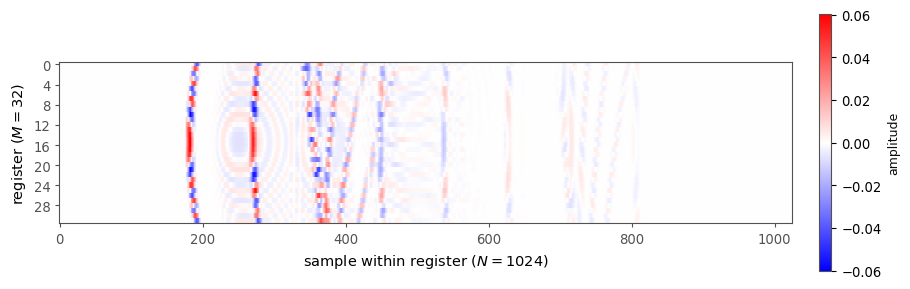

sub-dataset : rows 48..79 of 128   M = 32 registers x N = 1024 samples   ||Y|| = 1.000000
qubits      : n = 10 per register + m = 5 index = 15 for direct encoding
sigma_i     : sum sigma^2 = 1.0000000000   min 0.1280  max 0.2307


In [82]:
# Sub-dataset figure: the M = 32 x N = 1024 target used for the depth/runtime comparison.
#
# TRANSPOSED relative to the paper's other dataset figure: here the register index runs
# VERTICALLY and the sample index horizontally, so a 32 x 1024 array renders as a wide, short
# panel that fits the page width instead of a tall thin sliver. The axis labels disambiguate,
# but note it is the transpose of Fig. 3's orientation.
#
# Registers are labelled 0..M_SUB-1, i.e. indexed within the sub-dataset. They are rows
# 48..79 of the full 128-row image (the central block, which contains rows 62-65 -- the four
# encoded on H2-1), but that provenance belongs in the caption rather than on the axis.
#
# Reads only the raw excel sheet; nothing upstream needs to be run.
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.transform import resize

BASE = os.getcwd()
CMAP = "bwr"

FULL_N, FULL_M = 1024, 128
M_SUB      = 32
FIGSIZE    = (9.2, 3.0)
BOX_ASPECT = 0.22      # panel height / width. Lower = flatter. 32/1024 true aspect would be
                       # 0.03, unreadably thin, so the samples axis is compressed on purpose.
SHOW_HW    = False

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED = "#b7131e"

def frame(ax):
    """Image panels keep a thin full frame -- a heatmap reads oddly with no border at all."""
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)

_df  = pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None)
Y_x4 = resize(_df.to_numpy(), (FULL_N, FULL_M), anti_aliasing=True)
Y_x4 = Y_x4 / np.linalg.norm(Y_x4)

ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
Y_sub    = Y_x4[:, SUB_ROWS]
Y_sub    = Y_sub / np.linalg.norm(Y_sub)      # the sub-dataset is its own normalised state
img      = Y_sub.T                            # (32, 1024): rows = registers, cols = samples

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5, "ytick.labelsize": 9.5}):
    fig, ax = plt.subplots(figsize=FIGSIZE)

    vmax = np.abs(img).max()   # symmetric limits so white sits exactly at zero amplitude
    im = ax.imshow(img, aspect="auto", cmap=CMAP, interpolation="nearest",
                   vmin=-vmax, vmax=vmax)
    ax.set_xlabel(f"sample within register ($N = {FULL_N}$)")
    ax.set_ylabel(f"register ($M = {M_SUB}$)")
    ax.set_yticks(range(0, M_SUB, 4))
    ax.set_yticklabels([str(i) for i in range(0, M_SUB, 4)])
    ax.set_box_aspect(BOX_ASPECT)

    if SHOW_HW and all(r in SUB_ROWS for r in (62, 63, 64, 65)):
        a, b = SUB_ROWS.index(62) - 0.5, SUB_ROWS.index(65) + 0.5
        ax.add_patch(plt.Rectangle((-0.5, a), FULL_N, b - a, fill=False,
                                   edgecolor=RED, lw=1.3, ls="--", zorder=5))
        # label inside the panel: outside it collides with the colorbar. The far right of
        # the data is near-zero amplitude, so white text backing stays legible there.
        ax.text(FULL_N * 0.985, (a + b) / 2, "H2-1", color=RED, fontsize=8.5,
                ha="right", va="center", zorder=6,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.2, alpha=0.85))

    cb = fig.colorbar(im, ax=ax, fraction=0.020, pad=0.035)
    cb.outline.set_edgecolor(MUTED); cb.set_label("amplitude", fontsize=9, color=INK)
    frame(ax)

    fig.tight_layout()
    fig.savefig(os.path.join(BASE, f"fig_R75x4_dataset_M{M_SUB}.pdf"), bbox_inches="tight")
    plt.show()

_rn = np.linalg.norm(Y_sub.T, axis=1); _sig = _rn / np.linalg.norm(_rn)
print(f"sub-dataset : rows {SUB_ROWS[0]}..{SUB_ROWS[-1]} of {FULL_M}   "
      f"M = {M_SUB} registers x N = {FULL_N} samples   ||Y|| = {np.linalg.norm(Y_sub):.6f}")
print(f"qubits      : n = {int(np.log2(FULL_N))} per register + m = {int(np.log2(M_SUB))} index "
      f"= {int(np.log2(M_SUB*FULL_N))} for direct encoding")
print(f"sigma_i     : sum sigma^2 = {(_sig**2).sum():.10f}   "
      f"min {_sig.min():.4f}  max {_sig.max():.4f}")


  [R75x4_orig] numerical floor from depth 388 -- cut there
  [R75x4_orig] 32 rows, using depth 0..387
  [R75x4_M32_precond_L3] numerical floor from depth 396 -- cut there
  [R75x4_M32_precond_L3] 32 rows, using depth 0..395
  [direct M32] 1988 layers
  cutting every curve at Q-MERGE's deepest point: 10,473
  [Direct encoding] cropped to CNOT depth 10,473: 1739 layers of 1988


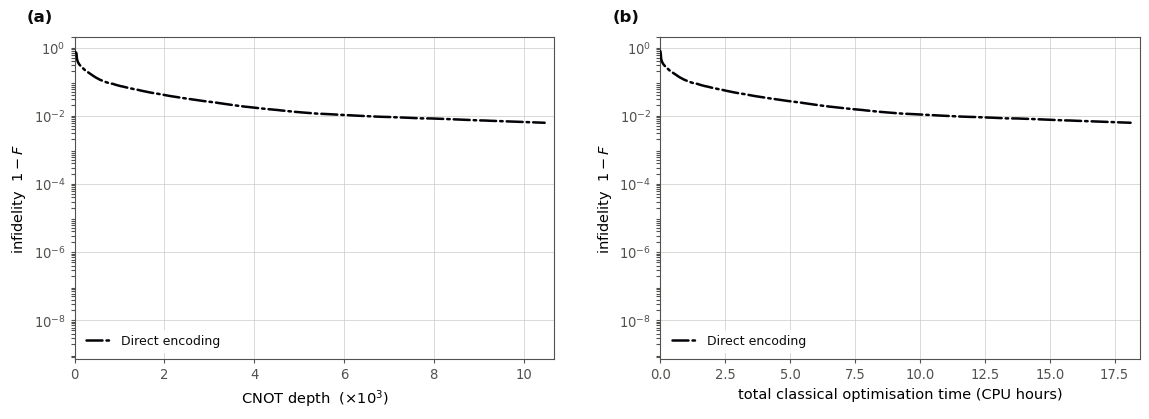

[1_direct] Direct encoding 6.18e-03


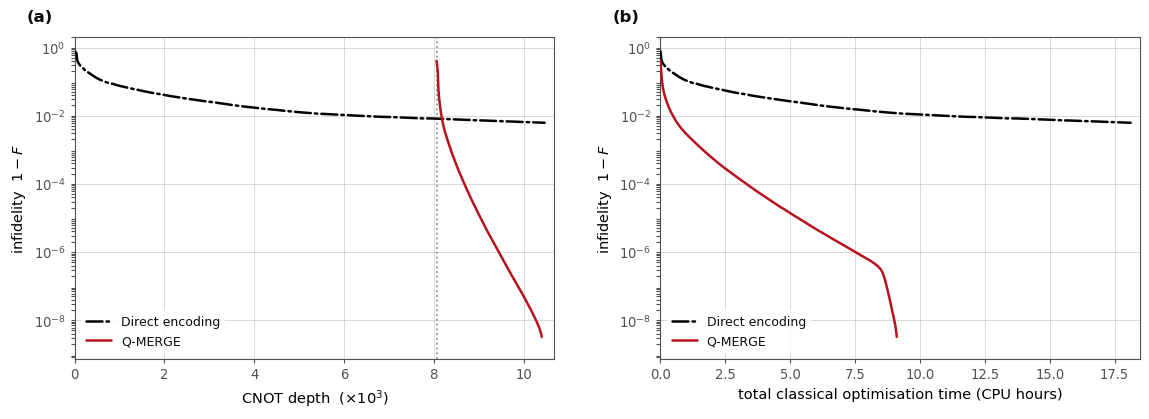

[2_direct_qmerge] Direct encoding 6.18e-03   Q-MERGE 3.22e-09


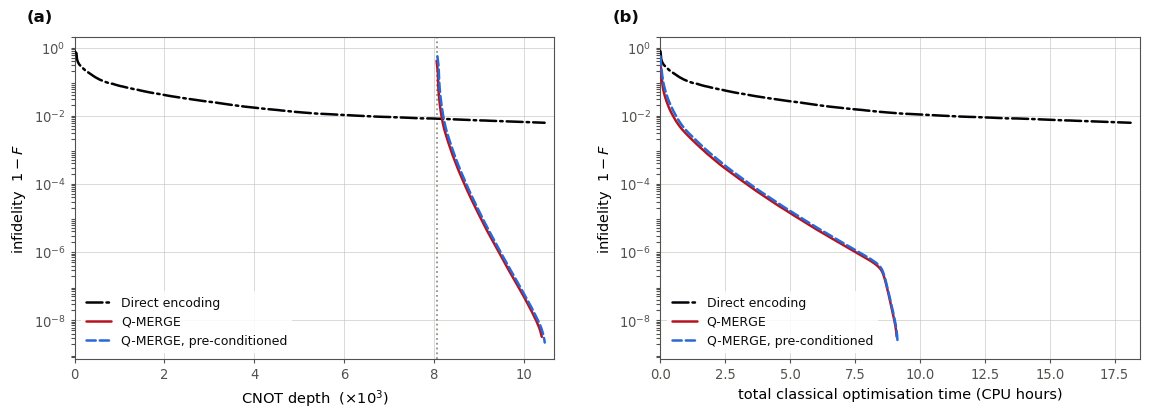

[3_direct_qmerge_precond] Direct encoding 6.18e-03   Q-MERGE 3.22e-09   Q-MERGE, pre-conditioned 2.19e-09
------------------------------------------------------------------------------
MERGE         8,064 = M(48m + 8n - 68)   [Stage 1 5,248 + Stage 2 2,816];  with V -> 8,082
CUT           CNOT depth 10,473
Direct encoding              1739 layers   depth  10,470   CPU 18.11 h   1-F = 6.183e-03
Q-MERGE                       387 layers   depth  10,407   CPU  9.11 h   1-F = 3.217e-09
Q-MERGE, pre-conditioned      395 layers   depth  10,473   CPU  9.14 h   1-F = 2.192e-09


In [93]:
# Slide build-up of the report's two-panel comparison (M = 32): one TWO-PANEL figure per
# step, (a) CNOT depth and (b) CPU hours, with curves revealed cumulatively:
#   1. direct encoding only
#   2. + Q-MERGE
#   3. + Q-MERGE, pre-conditioned
#
# IDENTICAL data handling to the report/collated figure -- same merge accounting, same
# CUT_TO_QMERGE, same FLOOR_TOL, same depth model, same interpolated rate model -- so the
# slides and the paper show the same curves on the same axes. Keep the knobs in sync.
#
# ONE Q-MERGE COST PER CURVE: the full Stages 1+2 merge. The report figure splits out the
# Stage-1-only variants for the supervisor; the slides deliberately do not, so each step of
# the build-up adds exactly one line.
#
# MERGE ACCOUNTING -- Jens's implementation, all in CNOT DEPTH:
#     m-controlled X : 2m-3 Toffolis (m-2 clean ancillas) = 12m - 18
#     Fredkin        : 8        rotation : 2 + controlled-Rz = 4
#   Stage 1, SELECT-SWAP compression (2 MCX + n Fredkins per segment) : M(24m + 8n - 36)
#   Stage 2, controlled rotations    (2 MCX + 1 rotation per segment) : M(24m - 32)
#   total merge                                                       : M(48m + 8n - 68)
#   For M=32, m=5, n=10: 5,248 + 2,816 = 8,064. Pre-conditioning V adds 6 L_V = 18.
#
# All frames share one axis scale per panel, computed from ALL curves after cutting, so
# advancing a slide reveals a line without anything else moving.
#
# Standalone: reads only files on disk. A run that is not complete is skipped and the frame
# list shortens accordingly, so this works mid-campaign.
import os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from skimage.transform import resize

BASE = os.getcwd()
TAG, FULL_M, FULL_N, n_row = "R75x4", 128, 1024, 10
M_SUB = 32
L_V   = 3            # brickwall pre-conditioning layers encoded (cell F1)

CUT_TO_QMERGE = True # crop every curve at Q-MERGE's deepest point -- the SAME rule as the
                     # report figure, so the slides end at the same depth it does.
CUT_CNOT  = None     # manual crop depth; used only when CUT_TO_QMERGE is False.
FLOOR_TOL = 1e-10    # automatic cut once any row hits the double-precision floor

# (depth, seconds per layer per row) anchors, linearly interpolated between. Per-layer cost
# is NOT constant: as SSO disentangles a row its Schmidt spectrum collapses, so the warm-start
# layer is nearly optimal and L-BFGS-B exits long before n_iter=200. Measured 3.7 s -> 0.45 s
# between depths 200 and 400.
RATE_ANCHORS = [(0, 3.75), (220, 3.70), (240, 3.70), (250, 2.98), (270, 0.80),
                (290, 0.50), (370, 0.50), (400, 0.45)]
RATE_DIRECT  = {14: 13.0, 15: 37.5}

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"
GUIDE = "#8a8a86"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

def prep_depth(n, L):
    """Two-qubit depth of L stacked chi=2 staircase layers on n qubits (ASAP schedule).
    The first layer costs the full 3(n-1); each further layer pipelines and adds only 6.
    Verified against pytket Circuit.depth(): n=10, L=379 -> 2295 = 3(9) + 6(378)."""
    L = np.asarray(L)
    return np.where(L <= 0, 0, 3 * (n - 1) + 6 * np.maximum(L - 1, 0))

def merge_stage1(N, M):
    m, n = int(math.log2(M)), int(math.log2(N))
    return M * (24 * m + 8 * n - 36)

def merge_stage2(M):
    return M * (24 * int(math.log2(M)) - 32)

def V_depth(L_V):
    """make_brick_wall_layer applies BOTH the even and odd sublayer per call, so one layer
    is 2 SU(4) deep = 6 CNOTs."""
    return 6 * L_V

def cum_hours_rows(n_layers, M):
    xs = np.array([a for a, _ in RATE_ANCHORS], float)
    ys = np.array([r for _, r in RATE_ANCHORS], float)
    per_layer = np.interp(np.arange(1, n_layers + 1), xs, ys)
    return np.concatenate([[0.0], np.cumsum(per_layer)]) * M / 3600.0

ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
n_sub    = int(round(np.log2(M_SUB * FULL_N)))

_Y = resize(pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None).to_numpy(),
            (FULL_N, FULL_M), anti_aliasing=True)
_Y = _Y / np.linalg.norm(_Y)
_sub = _Y[:, SUB_ROWS]; _sub = _sub / np.linalg.norm(_sub)
_rn  = np.linalg.norm(_sub.T, axis=1); sigma_sub = _rn / np.linalg.norm(_rn)

def _subset_infid(run_name, rows, sigma):
    folder = os.path.join(BASE, "SSO results", f"row_sweep_{run_name}")
    path = os.path.join(folder, "row_fids.json")
    if not os.path.exists(path):
        print(f"  [{run_name}] not started"); return None
    with open(path) as f:
        d = json.load(f)
    if any(str(i) not in d for i in rows):
        print(f"  [{run_name}] only {sum(str(i) in d for i in rows)}/{len(rows)} rows -- omitted")
        return None
    fids = [np.array(d[str(i)]["chi"]["2"]["chi_fids"], float) for i in rows]
    L = min(len(x) for x in fids)
    F = np.clip(np.array([x[:L] for x in fids]), 0.0, 1.0)
    worst = (1.0 - F).min(axis=0)
    ok = np.flatnonzero(worst > FLOOR_TOL)
    if ok.size and ok[-1] + 1 < F.shape[1]:
        print(f"  [{run_name}] numerical floor from depth {ok[-1]+1} -- cut there")
        F = F[:, :ok[-1] + 1]
    print(f"  [{run_name}] {len(rows)} rows, using depth 0..{F.shape[1]-1}")
    amp = (sigma[:, None] ** 2 * np.sqrt(F)).sum(axis=0)
    return np.clip(1.0 - np.clip(amp ** 2, 0.0, 1.0), 1e-16, None)

merge        = merge_stage1(FULL_N, M_SUB) + merge_stage2(M_SUB)   # Stages 1+2
merge_precon = merge + V_depth(L_V)
rate_D = RATE_DIRECT[n_sub]
KD = 1e-3

# ---------------- curves: (x_depth_raw, x_time, y, colour, style, label) ----------------
LINES = {}

infid_Q = _subset_infid(f"{TAG}_orig", SUB_ROWS, sigma_sub)
if infid_Q is not None:
    LINES["qmerge"] = (merge + prep_depth(n_row, np.arange(len(infid_Q))),
                       cum_hours_rows(len(infid_Q) - 1, M_SUB),
                       infid_Q, RED, "-", "Q-MERGE")

_pre_run = f"{TAG}_M{M_SUB}_precond_L{L_V}"
_pre_sig = os.path.join(BASE, "SSO results", f"row_sweep_{_pre_run}", "sigma.npy")
if os.path.exists(_pre_sig):
    infid_B = _subset_infid(_pre_run, list(range(M_SUB)), np.load(_pre_sig))
    if infid_B is not None:
        LINES["precond"] = (merge_precon + prep_depth(n_row, np.arange(len(infid_B))),
                            cum_hours_rows(len(infid_B) - 1, M_SUB),
                            infid_B, BLUE, "--", "Q-MERGE, pre-conditioned")
else:
    print(f"  [{_pre_run}] not started -- run cell F1")

SUB_CKPT = os.path.join(BASE, "SSO results", f"fullstate_{TAG}_M{M_SUB}", "checkpoint.npz")
if os.path.exists(SUB_CKPT):
    with np.load(SUB_CKPT) as ck:
        assert int(ck["M_sub"]) == M_SUB, f"checkpoint is M_sub={int(ck['M_sub'])}"
        yD = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)
    LINES["direct"] = (prep_depth(n_sub, np.arange(len(yD))),
                       np.arange(len(yD)) * rate_D / 3600.0,
                       yD, BLACK, "-.", "Direct encoding")
    print(f"  [direct M{M_SUB}] {len(yD)-1} layers")
else:
    print(f"  [direct] no checkpoint at {SUB_CKPT}")

# ---------------- crop every curve at the same CNOT depth ----------------
if CUT_TO_QMERGE:
    _ends = [LINES[k][0][-1] for k in ("qmerge", "precond") if k in LINES]
    assert _ends, "CUT_TO_QMERGE needs at least one Q-MERGE curve"
    CUT_CNOT = int(max(_ends))
    print(f"  cutting every curve at Q-MERGE's deepest point: {CUT_CNOT:,}")

if CUT_CNOT is not None:
    for k, (xd, xt, y, c, ls, lab) in list(LINES.items()):
        keep = xd <= CUT_CNOT
        if keep.sum() == 0:
            raise ValueError(f"CUT_CNOT = {CUT_CNOT:,} removes the whole '{lab}' curve, "
                             f"which starts at depth {xd[0]:,.0f}. Raise it above that.")
        if keep.sum() < len(xd):
            print(f"  [{lab}] cropped to CNOT depth {CUT_CNOT:,}: "
                  f"{keep.sum()-1} layers of {len(xd)-1}")
        LINES[k] = (xd[keep], xt[:keep.sum()], y[keep], c, ls, lab)

assert "direct" in LINES, "the build-up starts from the direct curve -- run cell D1"

ORDER   = [k for k in ("direct", "qmerge", "precond") if k in LINES]
FIGURES = [(f"{i+1}_" + "_".join(ORDER[:i+1]), ORDER[:i+1]) for i in range(len(ORDER))]

# ---- fixed scales, from ALL curves after cutting -> identical to the report figure ----
XMAX_D = max(v[0][-1] for v in LINES.values()) * KD * 1.02
XMAX_T = max(v[1][-1] for v in LINES.values()) * 1.02
YMIN   = min(v[2].min() for v in LINES.values()) / 3.0

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    for name, keys in FIGURES:
        fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.6, 4.3))
        axL.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
        axR.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
        # the merge marker belongs to Q-MERGE, so it appears with the first Q-MERGE curve
        if "qmerge" in keys or "precond" in keys:
            axL.axvline(merge * KD, color=GUIDE, ls=":", lw=1.3, alpha=0.95, zorder=1)

        for k in keys:
            xd, xt, y, c, ls, lab = LINES[k]
            axL.semilogy(xd * KD, y, ls=ls, lw=1.8, color=c, label=lab,
                         solid_capstyle="round", dash_capstyle="round", zorder=3)
            axR.semilogy(xt, y, ls=ls, lw=1.8, color=c, label=lab,
                         solid_capstyle="round", dash_capstyle="round", zorder=3)

        axL.set_xlabel(r"CNOT depth  ($\times 10^{3}$)")
        axR.set_xlabel("total classical optimisation time (CPU hours)")
        for ax, xmax in ((axL, XMAX_D), (axR, XMAX_T)):
            ax.set_ylabel(r"infidelity  $1-F$")
            ax.set_xlim(0, xmax); ax.set_ylim(YMIN, 2.0)
            ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1,
                                                  numticks=20))
            ax.yaxis.set_minor_formatter(NullFormatter())
            style_legend(ax, loc="lower left")
            tidy(ax)
        for ax, tag in ((axL, "(a)"), (axR, "(b)")):
            ax.text(-0.10, 1.04, tag, transform=ax.transAxes, fontsize=12,
                    fontweight="bold", color=INK, va="bottom", ha="left")

        fig.tight_layout(w_pad=3.0)
        fig.savefig(os.path.join(BASE, f"fig_{TAG}_buildup_M{M_SUB}_{name}.pdf"),
                    bbox_inches="tight")
        plt.show()
        print(f"[{name}] " + "   ".join(f"{LINES[k][5]} {LINES[k][2][-1]:.2e}" for k in keys))

print("-" * 78)
print(f"MERGE         {merge:,} = M(48m + 8n - 68)   "
      f"[Stage 1 {merge_stage1(FULL_N, M_SUB):,} + Stage 2 {merge_stage2(M_SUB):,}];  "
      f"with V -> {merge_precon:,}")
print(f"CUT           CNOT depth {CUT_CNOT:,}")
for k in ORDER:
    xd, xt, y, *_ , lab = LINES[k]
    print(f"{lab:<28} {len(y)-1:>4d} layers   depth {xd[-1]:>7,.0f}   "
          f"CPU {xt[-1]:>5.2f} h   1-F = {y[-1]:.3e}")


# A potential correction

  [R75x4_orig] numerical floor from depth 388 -- cut there
  [R75x4_orig] 32 rows, using depth 0..387
  [R75x4_M32_precond_L3] numerical floor from depth 396 -- cut there
  [R75x4_M32_precond_L3] 32 rows, using depth 0..395
  [direct M32] 1933 layers
  cutting every curve at Q-MERGE's deepest point: 10,473
  [Direct encoding] cropped to CNOT depth 10,473: 1739 layers of 1933


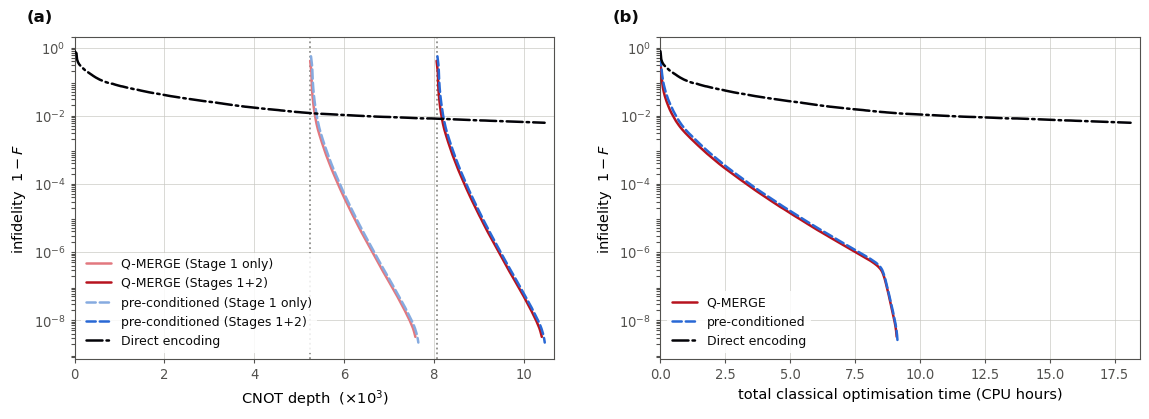

TARGET        M = 32 x N = 1024   (rows 48..79 of 128)
              Q-MERGE 336 qubits   direct 15 qubits
PREP DEPTH    first layer 27 (Q-MERGE) / 42 (direct); every further layer +6 for both (pipelined)
STAGE 1       5,248   = M(24m + 8n - 36), SELECT-SWAP network
STAGE 2       2,816   = M(24m - 32), controlled rotations
STAGES 1+2    8,064   = M(48m + 8n - 68);  with V +18 -> 8,082
CUT           CNOT depth 10,473
------------------------------------------------------------------------------
Q-MERGE (Stage 1 only)              387 layers   depth   7,591   CPU  9.11 h   1-F = 3.217e-09
Q-MERGE (Stages 1+2)                387 layers   depth  10,407   CPU  9.11 h   1-F = 3.217e-09
pre-conditioned (Stage 1 only)      395 layers   depth   7,657   CPU  9.14 h   1-F = 2.192e-09
pre-conditioned (Stages 1+2)        395 layers   depth  10,473   CPU  9.14 h   1-F = 2.192e-09
Direct encoding                    1739 layers   depth  10,470   CPU 18.11 h   1-F = 6.183e-03
at matched depth 10,407:  

In [88]:
# ===== Q-MERGE vs direct encoding: (a) CNOT depth, (b) total CPU time =====
# Reads whatever is on disk, so re-run as the sweeps deepen.
# Standalone: no SSO setup cell, no quimb, no A0.
#
# TARGET: the middle M_SUB registers of the 4x upscaled R75 data (rows 48..79 for M_SUB=32),
# which contains rows 62-65, the four encoded on H2-1.
#
# NOTHING is re-fitted here: each row's F_i was optimised against that row ALONE (normalised),
# so the saved row_sweep fidelities apply to any subset; only sigma_i is renormalised.
#
# PANEL (a) SHOWS FOUR Q-MERGE CURVES: each variant with the SELECT-SWAP network alone
# (Stage 1, light) and with the reweighting block added (Stages 1+2, dark). Two grey dotted
# lines mark where each starts. Panel (b) shows only the Stages 1+2 curves, because the
# Stage-1-only variants are the SAME optimisation runs and overlay exactly on a time axis.
#
# DEPTH MODEL -- every quantity on the (a) axis is a two-qubit DEPTH.
#   Building blocks:
#     m-controlled X : 2m-3 Toffolis (m-2 clean ancillas) = 12m-18
#     Fredkin        : 8
#     rotation       : 2 + controlled-Rz = 4
#   Stage 1, SELECT-SWAP compression, 2 MCX + n Fredkins per segment : M(24m + 8n - 36)
#   Stage 2, controlled rotations,    2 MCX + 1 rotation per segment : M(24m - 32)
#   total merge (excluding segment preparation and V-dagger)         : M(48m + 8n - 68)
#   Pre-conditioning V: 6 per brickwall layer -- make_brick_wall_layer applies an even and
#   an odd sublayer of DISJOINT gates, so each layer is exactly 2 SU(4) = 6 deep.
#
#   Segment / state preparation, L chi=2 staircase layers on n qubits:
#       prep_depth(n, L) = 3(n-1) + 6(L-1)
#   NOT 3(n-1)L. Within one staircase the gates chain, so the FIRST layer costs the full
#   3(n-1). But layer k+1 on qubits (0,1) waits only on layer k's gates touching qubits 0
#   and 1, so the stack pipelines into a diagonal wavefront and each further layer adds
#   exactly 2 SU(4) = 6, independent of n. Verified against pytket Circuit.depth():
#   n=10, L=379 -> 2295 = 3(9) + 6(378).
#
#   The M registers are prepared IN PARALLEL on hardware (Alg. 1), so Q-MERGE pays one
#   register's depth, not M times it. Direct pays prep_depth(n_sub, L), n_sub = log2(M N).
#
# TIME MODEL -- per-layer optimisation cost is NOT constant: as SSO disentangles a row its
# Schmidt spectrum collapses, so the warm-start layer is nearly optimal and L-BFGS-B exits
# long before n_iter=200. Measured 3.7 s -> 0.45 s per row per layer between depths 200-400.
import os, json, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from skimage.transform import resize

BASE = os.getcwd()
TAG, FULL_M, FULL_N, n_row = "R75x4", 128, 1024, 10
M_SUB = 32
L_V   = 3            # brickwall pre-conditioning layers encoded (cell F1)

CUT_TO_QMERGE = True # crop every curve at the deepest point Q-MERGE reaches, so direct
                     # ends exactly where Q-MERGE does and the plotted endpoints ARE the
                     # matched-depth comparison. Overrides CUT_CNOT when True.
CUT_CNOT  = None     # manual crop depth; None = no crop.
                     # NB must exceed s12 (Stage 1 + Stage 2) or those curves vanish.

FLOOR_TOL = 1e-10    # automatic cut once any row hits the double-precision floor

# (depth, seconds per layer per row) anchors, linearly interpolated between.
RATE_ANCHORS = [(0, 3.75), (220, 3.70), (240, 3.70), (250, 2.98), (270, 0.80),
                (290, 0.50), (370, 0.50), (400, 0.45)]
RATE_DIRECT  = {14: 13.0, 15: 37.5}   # measured medians; direct never converges here, so
                                      # it gets no speed-up

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"
RED_L, BLUE_L    = "#e2787f", "#86abe0"    # lighter shades for the Stage-1-only variants
GUIDE = "#8a8a86"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

def merge_stage1(N, M):
    m, n = int(math.log2(M)), int(math.log2(N))
    return M * (24 * m + 8 * n - 36)

def merge_stage2(M):
    return M * (24 * int(math.log2(M)) - 32)

def V_depth(L_V):
    return 6 * L_V

def prep_depth(n, L):
    """Two-qubit depth of L stacked chi=2 staircase layers on n qubits (ASAP schedule)."""
    L = np.asarray(L)
    return np.where(L <= 0, 0, 3 * (n - 1) + 6 * np.maximum(L - 1, 0))

def cum_hours_rows(n_layers, M):
    xs = np.array([a for a, _ in RATE_ANCHORS], float)
    ys = np.array([r for _, r in RATE_ANCHORS], float)
    per_layer = np.interp(np.arange(1, n_layers + 1), xs, ys)
    return np.concatenate([[0.0], np.cumsum(per_layer)]) * M / 3600.0

ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
n_sub    = int(round(np.log2(M_SUB * FULL_N)))

_Y = resize(pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None).to_numpy(),
            (FULL_N, FULL_M), anti_aliasing=True)
_Y = _Y / np.linalg.norm(_Y)
_sub = _Y[:, SUB_ROWS]; _sub = _sub / np.linalg.norm(_sub)
_rn  = np.linalg.norm(_sub.T, axis=1); sigma_sub = _rn / np.linalg.norm(_rn)

def _subset_infid(run_name, rows, sigma):
    folder = os.path.join(BASE, "SSO results", f"row_sweep_{run_name}")
    path = os.path.join(folder, "row_fids.json")
    if not os.path.exists(path):
        print(f"  [{run_name}] not started"); return None
    with open(path) as f:
        d = json.load(f)
    if any(str(i) not in d for i in rows):
        print(f"  [{run_name}] only {sum(str(i) in d for i in rows)}/{len(rows)} rows -- omitted")
        return None
    fids = [np.array(d[str(i)]["chi"]["2"]["chi_fids"], float) for i in rows]
    L = min(len(x) for x in fids)
    F = np.clip(np.array([x[:L] for x in fids]), 0.0, 1.0)
    worst = (1.0 - F).min(axis=0)
    ok = np.flatnonzero(worst > FLOOR_TOL)
    if ok.size and ok[-1] + 1 < F.shape[1]:
        print(f"  [{run_name}] numerical floor from depth {ok[-1]+1} -- cut there")
        F = F[:, :ok[-1] + 1]
    print(f"  [{run_name}] {len(rows)} rows, using depth 0..{F.shape[1]-1}")
    amp = (sigma[:, None] ** 2 * np.sqrt(F)).sum(axis=0)
    return np.clip(1.0 - np.clip(amp ** 2, 0.0, 1.0), 1e-16, None)

s1      = merge_stage1(FULL_N, M_SUB)     # SELECT-SWAP network (Stage 1)
s12     = s1 + merge_stage2(M_SUB)        # + reweighting block (Stage 2)
_vd     = V_depth(L_V)
s1_pre  = s1 + _vd
s12_pre = s12 + _vd
rate_D  = RATE_DIRECT[n_sub]
KD = 1e-3

# ---------------- curves: (x_depth_raw, x_time, y, colour, style, label) ----------------
LINES = {}

infid_Q = _subset_infid(f"{TAG}_orig", SUB_ROWS, sigma_sub)
if infid_Q is not None:
    _t = cum_hours_rows(len(infid_Q) - 1, M_SUB)
    _d = prep_depth(n_row, np.arange(len(infid_Q)))
    LINES["qmerge_s1"] = (s1 + _d, _t, infid_Q, RED_L, "-", "Q-MERGE (Stage 1 only)")
    LINES["qmerge"]    = (s12 + _d, _t, infid_Q, RED, "-", "Q-MERGE (Stages 1+2)")

_pre_run = f"{TAG}_M{M_SUB}_precond_L{L_V}"
_pre_sig = os.path.join(BASE, "SSO results", f"row_sweep_{_pre_run}", "sigma.npy")
if os.path.exists(_pre_sig):
    infid_B = _subset_infid(_pre_run, list(range(M_SUB)), np.load(_pre_sig))
    if infid_B is not None:
        _t = cum_hours_rows(len(infid_B) - 1, M_SUB)
        _d = prep_depth(n_row, np.arange(len(infid_B)))
        LINES["precond_s1"] = (s1_pre + _d, _t, infid_B, BLUE_L, "--",
                               "pre-conditioned (Stage 1 only)")
        LINES["precond"]    = (s12_pre + _d, _t, infid_B, BLUE, "--",
                               "pre-conditioned (Stages 1+2)")
else:
    print(f"  [{_pre_run}] not started -- run cell F1")

SUB_CKPT = os.path.join(BASE, "SSO results", f"fullstate_{TAG}_M{M_SUB}", "checkpoint.npz")
if os.path.exists(SUB_CKPT):
    with np.load(SUB_CKPT) as ck:
        assert int(ck["M_sub"]) == M_SUB, f"checkpoint is M_sub={int(ck['M_sub'])}"
        yD = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)
    LINES["direct"] = (prep_depth(n_sub, np.arange(len(yD))),
                       np.arange(len(yD)) * rate_D / 3600.0,
                       yD, BLACK, "-.", "Direct encoding")
    print(f"  [direct M{M_SUB}] {len(yD)-1} layers")
else:
    print(f"  [direct] no checkpoint at {SUB_CKPT}")
if CUT_TO_QMERGE:
    _ends = [LINES[k][0][-1] for k in ("qmerge", "precond") if k in LINES]
    assert _ends, "CUT_TO_QMERGE needs at least one Q-MERGE curve"
    CUT_CNOT = int(max(_ends))
    print(f"  cutting every curve at Q-MERGE's deepest point: {CUT_CNOT:,}")

if CUT_CNOT is not None:
    for k, (xd, xt, y, c, ls, lab) in list(LINES.items()):
        keep = xd <= CUT_CNOT
        if keep.sum() == 0:
            raise ValueError(f"CUT_CNOT = {CUT_CNOT:,} removes the whole '{lab}' curve, "
                             f"which starts at depth {xd[0]:,.0f}. Raise it above that.")
        if keep.sum() < len(xd):
            print(f"  [{lab}] cropped to CNOT depth {CUT_CNOT:,}: "
                  f"{keep.sum()-1} layers of {len(xd)-1}")
        LINES[k] = (xd[keep], xt[:keep.sum()], y[keep], c, ls, lab)

assert LINES, "nothing on disk yet"

XMAX_D = max(v[0][-1] for v in LINES.values()) * KD * 1.02
XMAX_T = max(v[1][-1] for v in LINES.values()) * 1.02
YMIN   = min(v[2].min() for v in LINES.values()) / 3.0

with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 9}):
    fig, (axL, axR) = plt.subplots(1, 2, figsize=(11.6, 4.3))
    axL.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
    axR.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
    for _g in (s1, s12):
        axL.axvline(_g * KD, color=GUIDE, ls=":", lw=1.3, alpha=0.95, zorder=1)

    for k in ("qmerge_s1", "qmerge", "precond_s1", "precond", "direct"):
        if k not in LINES: continue
        xd, xt, y, c, ls, lab = LINES[k]
        axL.semilogy(xd * KD, y, ls=ls, lw=1.8, color=c, label=lab,
                     solid_capstyle="round", dash_capstyle="round", zorder=3)
        if k.endswith("_s1"): continue
        axR.semilogy(xt, y, ls=ls, lw=1.8, color=c,
                     label=lab.replace(" (Stages 1+2)", ""),
                     solid_capstyle="round", dash_capstyle="round", zorder=3)

    axL.set_xlabel(r"CNOT depth  ($\times 10^{3}$)")
    axR.set_xlabel("total classical optimisation time (CPU hours)")
    for ax, xmax in ((axL, XMAX_D), (axR, XMAX_T)):
        ax.set_ylabel(r"infidelity  $1-F$")
        ax.set_xlim(0, xmax); ax.set_ylim(YMIN, 2.0)
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1, numticks=20))
        ax.yaxis.set_minor_formatter(NullFormatter())
        style_legend(ax, loc="lower left")
        tidy(ax)
    for ax, tag in ((axL, "(a)"), (axR, "(b)")):
        ax.text(-0.10, 1.04, tag, transform=ax.transAxes, fontsize=12,
                fontweight="bold", color=INK, va="bottom", ha="left")

    fig.tight_layout(w_pad=3.0)
    fig.savefig(os.path.join(BASE, f"fig_{TAG}_depth_and_time_M{M_SUB}.pdf"), bbox_inches="tight")
    plt.show()

print("=" * 78)
print(f"TARGET        M = {M_SUB} x N = {FULL_N}   (rows {SUB_ROWS[0]}..{SUB_ROWS[-1]} of {FULL_M})")
print(f"              Q-MERGE {M_SUB*n_row + n_row + int(math.log2(M_SUB)) + 1} qubits   "
      f"direct {n_sub} qubits")
print(f"PREP DEPTH    first layer {3*(n_row-1)} (Q-MERGE) / {3*(n_sub-1)} (direct); "
      f"every further layer +6 for both (pipelined)")
print(f"STAGE 1       {s1:,}   = M(24m + 8n - 36), SELECT-SWAP network")
print(f"STAGE 2       {merge_stage2(M_SUB):,}   = M(24m - 32), controlled rotations")
print(f"STAGES 1+2    {s12:,}   = M(48m + 8n - 68);  with V +{_vd} -> {s12_pre:,}")
print(f"CUT           CNOT depth {CUT_CNOT:,}" if CUT_CNOT else "CUT           none")
print("-" * 78)
for k in ("qmerge_s1", "qmerge", "precond_s1", "precond", "direct"):
    if k not in LINES: continue
    xd, xt, y, c, ls, lab = LINES[k]
    print(f"{lab:<34} {len(y)-1:>4d} layers   depth {xd[-1]:>7,.0f}   "
          f"CPU {xt[-1]:>5.2f} h   1-F = {y[-1]:.3e}")
if "qmerge" in LINES and "direct" in LINES:
    xq, tq, yq, *_ = LINES["qmerge"]; xdd, td, yd, *_ = LINES["direct"]
    if xdd[-1] >= xq[0]:
        dmax = min(xq[-1], xdd[-1])
        q  = yq[max(np.searchsorted(xq, dmax) - 1, 0)]
        dd = yd[max(np.searchsorted(xdd, dmax) - 1, 0)]
        print(f"at matched depth {dmax:,.0f}:  Q-MERGE {q:.3e}  vs  direct {dd:.3e}  ({dd/q:,.0f}x)")
    else:
        print(f"NO OVERLAP IN DEPTH: direct ends at {xdd[-1]:,.0f}, Q-MERGE starts at "
              f"{xq[0]:,.0f}.")
    need = int((xq[-1] - 3*(n_sub-1)) / 6) + 1
    print(f"To reach Q-MERGE's {xq[-1]:,.0f}, direct needs ~{need:,} layers "
          f"(~{need*rate_D/3600:.1f} h at {rate_D} s/layer).")
print("=" * 78)


  [R75x4_orig] numerical floor from depth 388 -- cut there
  [R75x4_orig] 32 rows, using depth 0..387
  [R75x4_M32_precond_L3] numerical floor from depth 396 -- cut there
  [R75x4_M32_precond_L3] 32 rows, using depth 0..395
  [direct M32] 1954 layers
  cutting every curve at Q-MERGE's deepest point: 10,473
  [Direct encoding] cropped to CNOT depth 10,473: 1739 layers of 1954
  [success] v_R75x4_M32_incr.pkl, layer 3: P 0.0098 -> 0.3170


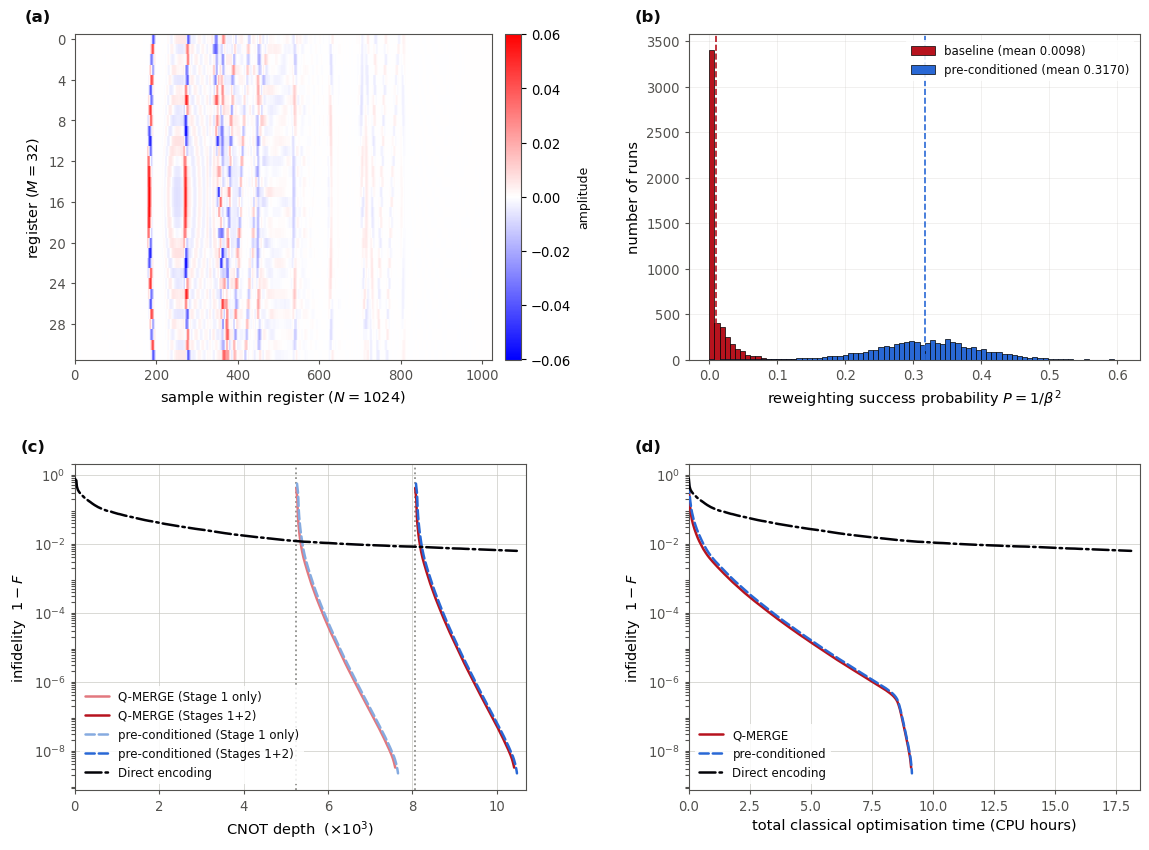

SAVED         fig_R75x4_collated_M32.pdf
TARGET        M = 32 x N = 1024   (rows 48..79 of 128)   ||Y|| = 1.000000
              Q-MERGE 336 qubits   direct 15 qubits
sigma_i       sum sigma^2 = 1.0000000000   min 0.1280  max 0.2307
------------------------------------------------------------------------------
(b) baseline  mean P = 0.0098 (converged, 100k shots)   median 0.00033   histogram from 5000 shots (own mean 0.0102 +/- 0.0003)
(b) 3 layers mean P = 0.3170 +/- 0.0011   median 0.32060   (5000 shots)   -> 32.3x for 18 CNOT depth
(b) IPR       4.5831e-05   (1.502x the uniform floor 3.052e-05)
------------------------------------------------------------------------------
STAGE 1       5,248   = M(24m + 8n - 36), SELECT-SWAP network
STAGE 2       2,816   = M(24m - 32), controlled rotations
STAGES 1+2    8,064   = M(48m + 8n - 68);  with V +18 -> 8,082
CUT           CNOT depth 10,473
------------------------------------------------------------------------------
Q-MERGE (Stage 1 only)

In [91]:
# ===== COLLATED FIGURE: the whole M = 32 story in one 2x2 panel =====
#   (a) the sub-dataset            (b) reweighting success
#   (c) infidelity vs CNOT depth   (d) infidelity vs CPU time
#
# This is the dataset cell, the success-histogram cell and the depth/time cell merged, with
# IDENTICAL data handling in each -- same sigma renormalisation, same BASE_MEAN, same
# CUT_TO_QMERGE, same FLOOR_TOL -- so the collated figure and the three standalone figures
# cannot disagree. Panels whose inputs are missing are left blank with a note rather than
# failing, so this works mid-campaign.
#
# ALL FOUR PANELS share the grid's natural aspect -- no set_box_aspect anywhere, so (b), (c)
# and (d) keep the proportions they have as standalone figures. Panel (a) is an imshow with
# aspect="auto", so it simply fills its cell; DATA_ASPECT flattens it if you want the image
# shorter than the plots. The true 32 x 1024 aspect is 0.03, unreadably thin, so the sample
# axis is compressed on purpose; the axis labels carry the real shape. Transposed relative to
# the paper's Fig. 3: register index runs vertically here.
#
# MERGE ACCOUNTING -- Jens's implementation, all in CNOT DEPTH:
#     m-controlled X : 2m-3 Toffolis (m-2 clean ancillas) = 12m - 18
#     Fredkin        : 8        rotation : 2 + controlled-Rz = 4
#   Stage 1, SELECT-SWAP compression (2 MCX + n Fredkins per segment) : M(24m + 8n - 36)
#   Stage 2, controlled rotations    (2 MCX + 1 rotation per segment) : M(24m - 32)
#   total merge                                                       : M(48m + 8n - 68)
#   For M=32, m=5, n=10: Stage 1 = 5,248   Stage 2 = 2,816   total = 8,064. V adds 6 L_V = 18.
#
# SEGMENT PREPARATION, L chi=2 staircase layers on n qubits:
#       prep_depth(n, L) = 3(n-1) + 6(L-1)
#   NOT 3(n-1)L -- the stack pipelines into a diagonal wavefront, so each layer past the first
#   adds exactly 2 SU(4) = 6, independent of n. Verified against pytket Circuit.depth():
#   n=10, L=379 -> 2295 = 3(9) + 6(378). The M registers are prepared IN PARALLEL (Alg. 1),
#   so Q-MERGE pays ONE register's depth; direct pays prep_depth(n_sub, L), n_sub = log2(M N).
import os, glob, json, math, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import LogLocator, NullFormatter
from skimage.transform import resize

BASE = os.getcwd()
TAG, FULL_M, FULL_N, n_row = "R75x4", 128, 1024, 10
M_SUB = 32
L_V   = 3            # brickwall pre-conditioning layers encoded (cell F1)

CUT_TO_QMERGE = True # crop every depth curve at Q-MERGE's deepest point, so direct ends
                     # exactly where Q-MERGE does and the plotted endpoints ARE the
                     # matched-depth comparison. Overrides CUT_CNOT.
CUT_CNOT  = None
FLOOR_TOL = 1e-10    # automatic cut once any row hits the double-precision floor

SHOW_L     = 3       # pre-conditioning depth shown in (b); None = best in file
NBINS      = 81
BASE_MEAN  = 0.0098  # converged baseline P, 100k shots (+/- 0.0001). The 5000-shot estimate
                     # stored in the pickle swings 0.0094-0.0102 because P is a skewed tail
                     # statistic (median ~3e-4 against mean ~1e-2).
CMAP        = "bwr"
FIGSIZE     = (11.6, 8.6)
DATA_ASPECT = None   # panel (a) height/width. None = fill the cell like the other three.
                     # Set e.g. 0.5 to make the data image shorter than the plots.

RATE_ANCHORS = [(0, 3.75), (220, 3.70), (240, 3.70), (250, 2.98), (270, 0.80),
                (290, 0.50), (370, 0.50), (400, 0.45)]
RATE_DIRECT  = {14: 13.0, 15: 37.5}

INK, MUTED, GRID = "#0b0b0b", "#52514e", "#c9c8c3"
RED, BLUE, BLACK = "#b7131e", "#2968d5", "#020207"
RED_L, BLUE_L    = "#e2787f", "#86abe0"   # lighter shades for the Stage-1-only variants
GUIDE = "#8a8a86"

def tidy(ax):
    for s in ax.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    ax.tick_params(colors=MUTED, which="both", length=3, width=0.8)
    ax.set_axisbelow(True)

def style_legend(ax, **kw):
    return ax.legend(frameon=True, facecolor="white", edgecolor="none",
                     framealpha=0.85, labelcolor=INK, **kw)

def merge_stage1(N, M):
    m, n = int(math.log2(M)), int(math.log2(N))
    return M * (24 * m + 8 * n - 36)

def merge_stage2(M):
    return M * (24 * int(math.log2(M)) - 32)

def V_depth(L_V):
    """make_brick_wall_layer applies BOTH the even and odd sublayer per call, so one layer
    is 2 SU(4) deep = 6 CNOTs."""
    return 6 * L_V

def prep_depth(n, L):
    L = np.asarray(L)
    return np.where(L <= 0, 0, 3 * (n - 1) + 6 * np.maximum(L - 1, 0))

def cum_hours_rows(n_layers, M):
    xs = np.array([a for a, _ in RATE_ANCHORS], float)
    ys = np.array([r for _, r in RATE_ANCHORS], float)
    per_layer = np.interp(np.arange(1, n_layers + 1), xs, ys)
    return np.concatenate([[0.0], np.cumsum(per_layer)]) * M / 3600.0

# ---------------- shared target definition ----------------
ROW_LO   = FULL_M // 2 - M_SUB // 2
SUB_ROWS = list(range(ROW_LO, ROW_LO + M_SUB))
n_sub    = int(round(np.log2(M_SUB * FULL_N)))
FLOOR_P  = 1.0 / 2 ** n_sub

_Y = resize(pd.read_excel(os.path.join(BASE, "R75 Ultrasound data.xlsx"), header=None).to_numpy(),
            (FULL_N, FULL_M), anti_aliasing=True)
_Y   = _Y / np.linalg.norm(_Y)
Y_sub = _Y[:, SUB_ROWS]; Y_sub = Y_sub / np.linalg.norm(Y_sub)
img   = Y_sub.T                                  # (32, 1024): rows = registers
_rn   = np.linalg.norm(Y_sub.T, axis=1); sigma_sub = _rn / np.linalg.norm(_rn)

def _subset_infid(run_name, rows, sigma):
    """1-F per layer over `rows`, truncated to the depth they ALL share, then cut before the
    double-precision floor.  F = (sum_i sigma_i^2 sqrt(F_i))^2."""
    path = os.path.join(BASE, "SSO results", f"row_sweep_{run_name}", "row_fids.json")
    if not os.path.exists(path):
        print(f"  [{run_name}] not started"); return None
    with open(path) as f:
        d = json.load(f)
    if any(str(i) not in d for i in rows):
        print(f"  [{run_name}] only {sum(str(i) in d for i in rows)}/{len(rows)} rows -- omitted")
        return None
    fids = [np.array(d[str(i)]["chi"]["2"]["chi_fids"], float) for i in rows]
    L = min(len(x) for x in fids)
    F = np.clip(np.array([x[:L] for x in fids]), 0.0, 1.0)
    worst = (1.0 - F).min(axis=0)
    ok = np.flatnonzero(worst > FLOOR_TOL)
    if ok.size and ok[-1] + 1 < F.shape[1]:
        print(f"  [{run_name}] numerical floor from depth {ok[-1]+1} -- cut there")
        F = F[:, :ok[-1] + 1]
    print(f"  [{run_name}] {len(rows)} rows, using depth 0..{F.shape[1]-1}")
    amp = (sigma[:, None] ** 2 * np.sqrt(F)).sum(axis=0)
    return np.clip(1.0 - np.clip(amp ** 2, 0.0, 1.0), 1e-16, None)

s1      = merge_stage1(FULL_N, M_SUB)      # SELECT-SWAP network   (Stage 1)
s12     = s1 + merge_stage2(M_SUB)         # + reweighting block   (Stages 1+2)
_vd     = V_depth(L_V)
s1_pre, s12_pre = s1 + _vd, s12 + _vd
rate_D  = RATE_DIRECT[n_sub]
KD = 1e-3

# ---------------- (c)/(d) curves: (x_depth, x_time, y, colour, style, label) ----------------
LINES = {}

infid_Q = _subset_infid(f"{TAG}_orig", SUB_ROWS, sigma_sub)
if infid_Q is not None:
    _t = cum_hours_rows(len(infid_Q) - 1, M_SUB)
    _d = prep_depth(n_row, np.arange(len(infid_Q)))
    LINES["qmerge_s1"] = (s1  + _d, _t, infid_Q, RED_L, "-", "Q-MERGE (Stage 1 only)")
    LINES["qmerge"]    = (s12 + _d, _t, infid_Q, RED,   "-", "Q-MERGE (Stages 1+2)")

_pre_run = f"{TAG}_M{M_SUB}_precond_L{L_V}"
_pre_sig = os.path.join(BASE, "SSO results", f"row_sweep_{_pre_run}", "sigma.npy")
if os.path.exists(_pre_sig):
    infid_B = _subset_infid(_pre_run, list(range(M_SUB)), np.load(_pre_sig))
    if infid_B is not None:
        _t = cum_hours_rows(len(infid_B) - 1, M_SUB)
        _d = prep_depth(n_row, np.arange(len(infid_B)))
        LINES["precond_s1"] = (s1_pre  + _d, _t, infid_B, BLUE_L, "--",
                               "pre-conditioned (Stage 1 only)")
        LINES["precond"]    = (s12_pre + _d, _t, infid_B, BLUE,   "--",
                               "pre-conditioned (Stages 1+2)")
else:
    print(f"  [{_pre_run}] not started -- run cell F1")

SUB_CKPT = os.path.join(BASE, "SSO results", f"fullstate_{TAG}_M{M_SUB}", "checkpoint.npz")
if os.path.exists(SUB_CKPT):
    with np.load(SUB_CKPT) as ck:
        assert int(ck["M_sub"]) == M_SUB, f"checkpoint is M_sub={int(ck['M_sub'])}"
        yD = np.clip(1.0 - np.array(ck["chi_fids"], float), 1e-16, None)
    LINES["direct"] = (prep_depth(n_sub, np.arange(len(yD))),
                       np.arange(len(yD)) * rate_D / 3600.0,
                       yD, BLACK, "-.", "Direct encoding")
    print(f"  [direct M{M_SUB}] {len(yD)-1} layers")
else:
    print(f"  [direct] no checkpoint at {SUB_CKPT}")

if CUT_TO_QMERGE and LINES:
    _ends = [LINES[k][0][-1] for k in ("qmerge", "precond") if k in LINES]
    if _ends:
        CUT_CNOT = int(max(_ends))
        print(f"  cutting every curve at Q-MERGE's deepest point: {CUT_CNOT:,}")

if CUT_CNOT is not None:
    for k, (xd, xt, y, c, ls, lab) in list(LINES.items()):
        keep = xd <= CUT_CNOT
        if keep.sum() == 0:
            raise ValueError(f"CUT_CNOT = {CUT_CNOT:,} removes the whole '{lab}' curve, "
                             f"which starts at depth {xd[0]:,.0f}. Raise it above that.")
        if keep.sum() < len(xd):
            print(f"  [{lab}] cropped to CNOT depth {CUT_CNOT:,}: "
                  f"{keep.sum()-1} layers of {len(xd)-1}")
        LINES[k] = (xd[keep], xt[:keep.sum()], y[keep], c, ls, lab)

# ---------------- (b) reweighting success ----------------
HIST = None
_paths = sorted(glob.glob(os.path.join(BASE, "results", f"v_{TAG}_M{M_SUB}_*.pkl")))
_cands = []
for p in _paths:
    with open(p, "rb") as f:
        _d = pickle.load(f)
    for L, r in _d.get("layer_results", {}).items():
        _cands.append((r["res"]["mean"], L, p, _d))
if not _cands:
    print(f"  [success] no completed layers in results/v_{TAG}_M{M_SUB}_*.pkl -- run cell E1")
else:
    _sel = _cands if SHOW_L is None else [c for c in _cands if c[1] == SHOW_L]
    assert _sel, f"no file contains layer {SHOW_L}"
    _bP, _bL, _bpath, _bdata = max(_sel, key=lambda t: t[0])
    _r = _bdata["layer_results"][_bL]
    assert _r["ipr"] / FLOOR_P > 1.05, (
        f"layer {_bL} sits on the uniform IPR floor ({_r['ipr']/FLOOR_P:.4f}x) -- the "
        f"non-unitary-V signature. Delete {os.path.basename(_bpath)} and re-run E1.")
    P0, P1 = np.asarray(_bdata["base_result"]["P"]), np.asarray(_r["res"]["P"])
    HIST = (P0, BASE_MEAN, P1, _r["res"]["mean"], _bL, _bpath, _r["ipr"], _bdata)
    print(f"  [success] {os.path.basename(_bpath)}, layer {_bL}: "
          f"P {BASE_MEAN:.4f} -> {_r['res']['mean']:.4f}")

# ================================ draw ================================
with plt.rc_context({"pdf.fonttype": 42, "ps.fonttype": 42, "font.size": 10,
                     "axes.labelsize": 10.5, "xtick.labelsize": 9.5,
                     "ytick.labelsize": 9.5, "legend.fontsize": 8.5}):
    fig, axes = plt.subplots(2, 2, figsize=FIGSIZE)
    (axA, axB), (axC, axD) = axes

    # ---- (a) the sub-dataset ----
    vmax = np.abs(img).max()        # symmetric limits so white sits exactly at zero amplitude
    im = axA.imshow(img, aspect="auto", cmap=CMAP, interpolation="nearest",
                    vmin=-vmax, vmax=vmax)
    axA.set_xlabel(f"sample within register ($N = {FULL_N}$)")
    axA.set_ylabel(f"register ($M = {M_SUB}$)")
    axA.set_yticks(range(0, M_SUB, 4))
    if DATA_ASPECT is not None:
        axA.set_box_aspect(DATA_ASPECT)
    cb = fig.colorbar(im, ax=axA, fraction=0.046, pad=0.03)
    cb.outline.set_edgecolor(MUTED); cb.set_label("amplitude", fontsize=9, color=INK)
    for s in axA.spines.values():
        s.set_visible(True); s.set_color(MUTED); s.set_linewidth(0.8)
    axA.tick_params(colors=MUTED, which="both", length=3, width=0.8)

    # ---- (b) reweighting success ----
    if HIST is None:
        axB.text(0.5, 0.5, "no reweighting run on disk\n(run cell E1)", ha="center",
                 va="center", transform=axB.transAxes, color=MUTED, fontsize=9)
        axB.set_xticks([]); axB.set_yticks([])
    else:
        P0, m0, P1, m1, _bL, _bpath, _ipr, _bdata = HIST
        bins = np.linspace(min(P0.min(), P1.min()), max(P0.max(), P1.max()) * 1.02, NBINS)
        axB.grid(alpha=0.3, zorder=0, lw=0.6, color=GRID)
        for P, mean, c, lab in ((P0, m0, RED,  f"baseline (mean {m0:.4f})"),
                                (P1, m1, BLUE, f"pre-conditioned (mean {m1:.4f})")):
            axB.hist(P, bins=bins, color=c, edgecolor="black", lw=0.5, label=lab, zorder=2)
            axB.axvline(mean, color=c, ls="--", lw=1.2, zorder=3)
        axB.set_xlabel(r"reweighting success probability $P = 1/\beta^2$")
        axB.set_ylabel("number of runs")
        style_legend(axB, loc="upper right")
    tidy(axB)

    # ---- (c) depth and (d) CPU time ----
    for _g in (s1, s12):            # upfront merge cost: Stage 1, then Stages 1+2
        axC.axvline(_g * KD, color=GUIDE, ls=":", lw=1.3, alpha=0.95, zorder=1)
    axC.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)
    axD.grid(True, which="major", lw=0.6, color=GRID, alpha=0.8)

    # (c) shows all four Q-MERGE variants; (d) only Stages 1+2 -- the Stage-1-only curves are
    # the SAME optimisation runs and would overlay exactly on a time axis.
    for k in ("qmerge_s1", "qmerge", "precond_s1", "precond", "direct"):
        if k not in LINES: continue
        xd, xt, y, c, ls, lab = LINES[k]
        axC.semilogy(xd * KD, y, ls=ls, lw=1.8, color=c, label=lab,
                     solid_capstyle="round", dash_capstyle="round", zorder=3)
        if k.endswith("_s1"): continue
        axD.semilogy(xt, y, ls=ls, lw=1.8, color=c, label=lab.replace(" (Stages 1+2)", ""),
                     solid_capstyle="round", dash_capstyle="round", zorder=3)

    if LINES:
        XMAX_D = max(v[0][-1] for v in LINES.values()) * KD * 1.02
        XMAX_T = max(v[1][-1] for v in LINES.values()) * 1.02
        YMIN   = min(v[2].min() for v in LINES.values()) / 3.0
    else:
        for ax in (axC, axD):
            ax.text(0.5, 0.5, "no SSO sweeps on disk", ha="center", va="center",
                    transform=ax.transAxes, color=MUTED, fontsize=9)
        XMAX_D, XMAX_T, YMIN = 1, 1, 1e-9

    axC.set_xlabel(r"CNOT depth  ($\times 10^{3}$)")
    axD.set_xlabel("total classical optimisation time (CPU hours)")
    for ax, xmax in ((axC, XMAX_D), (axD, XMAX_T)):
        ax.set_ylabel(r"infidelity  $1-F$")
        ax.set_xlim(0, xmax); ax.set_ylim(YMIN, 2.0)
        ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1,
                                              numticks=20))
        ax.yaxis.set_minor_formatter(NullFormatter())
        if LINES: style_legend(ax, loc="lower left")
        tidy(ax)

    for ax, tag in ((axA, "(a)"), (axB, "(b)"), (axC, "(c)"), (axD, "(d)")):
        ax.text(-0.12, 1.03, tag, transform=ax.transAxes, fontsize=12,
                fontweight="bold", color=INK, va="bottom", ha="left")

    fig.tight_layout(w_pad=2.6, h_pad=2.2)
    OUT = os.path.join(BASE, f"fig_{TAG}_collated_M{M_SUB}.pdf")
    fig.savefig(OUT, bbox_inches="tight")
    plt.show()

# ================================ numbers ================================
print("=" * 78)
print(f"SAVED         {os.path.basename(OUT)}")
print(f"TARGET        M = {M_SUB} x N = {FULL_N}   (rows {SUB_ROWS[0]}..{SUB_ROWS[-1]} "
      f"of {FULL_M})   ||Y|| = {np.linalg.norm(Y_sub):.6f}")
print(f"              Q-MERGE {M_SUB*n_row + n_row + int(math.log2(M_SUB)) + 1} qubits   "
      f"direct {n_sub} qubits")
print(f"sigma_i       sum sigma^2 = {(sigma_sub**2).sum():.10f}   "
      f"min {sigma_sub.min():.4f}  max {sigma_sub.max():.4f}")
print("-" * 78)
if HIST is not None:
    P0, m0, P1, m1, _bL, _bpath, _ipr, _bdata = HIST
    _s0 = P0.std(ddof=1) / np.sqrt(len(P0)); _s1 = P1.std(ddof=1) / np.sqrt(len(P1))
    print(f"(b) baseline  mean P = {m0:.4f} (converged, 100k shots)   "
          f"median {np.median(P0):.5f}   histogram from {len(P0)} shots "
          f"(own mean {_bdata['base_result']['mean']:.4f} +/- {_s0:.4f})")
    print(f"(b) {_bL} layers mean P = {m1:.4f} +/- {_s1:.4f}   median {np.median(P1):.5f}   "
          f"({len(P1)} shots)   -> {m1/m0:.1f}x for {6*_bL} CNOT depth")
    print(f"(b) IPR       {_ipr:.4e}   ({_ipr/FLOOR_P:.3f}x the uniform floor {FLOOR_P:.3e})")
    print("-" * 78)
print(f"STAGE 1       {s1:,}   = M(24m + 8n - 36), SELECT-SWAP network")
print(f"STAGE 2       {merge_stage2(M_SUB):,}   = M(24m - 32), controlled rotations")
print(f"STAGES 1+2    {s12:,}   = M(48m + 8n - 68);  with V +{_vd} -> {s12_pre:,}")
print(f"CUT           CNOT depth {CUT_CNOT:,}" if CUT_CNOT else "CUT           none")
print("-" * 78)
for k in ("qmerge_s1", "qmerge", "precond_s1", "precond", "direct"):
    if k not in LINES: continue
    xd, xt, y, c, ls, lab = LINES[k]
    print(f"{lab:<34} {len(y)-1:>4d} layers   depth {xd[-1]:>7,.0f}   "
          f"CPU {xt[-1]:>5.2f} h   1-F = {y[-1]:.3e}")
if "qmerge" in LINES and "direct" in LINES:
    xq, _, yq, *_ = LINES["qmerge"]; xdd, _, yd, *_ = LINES["direct"]
    dmax = min(xq[-1], xdd[-1])
    q  = yq[max(np.searchsorted(xq, dmax) - 1, 0)]
    dd = yd[max(np.searchsorted(xdd, dmax) - 1, 0)]
    print(f"at matched depth {dmax:,.0f}:  Q-MERGE {q:.3e}  vs  direct {dd:.3e}  ({dd/q:,.0f}x)")
print("=" * 78)

